# Bar type and sampling frequency: what happens to the four primary strategies, and what is meta-labeling worth?

**Question.** For the four primary strategies of `quant_forge.strategies` (RSI cross-above, Donchian breakout continuation,
TIS momentum confluence, SuperTrend regime confluence) with their default entry and exit rules, on the 40-asset Binance spot
universe of the reference notebook (`meta_labeling_economic_value_quant_forge.ipynb`, 20 `SEEN` assets for training and 20
`NEW` assets for transfer): **how do the bar type (time, volume, dollar) and the sampling frequency (48, 24, 6 and 1 bars per
day) change the primary strategies, and how much economic value does meta-labeling add in each configuration?**

**Design in one paragraph.** Twelve bar configurations: time bars of 30 minutes, 1 hour, 4 hours and 1 day (Binance klines),
and volume and dollar bars targeting the same average frequencies, built from the complete Binance aggTrades archive
(≈ 16 billion trades) with a threshold estimated **per asset from the trailing 30 complete days of traded volume** (known before
any bar of the day opens), so that the realised frequency rises and falls with market activity. On every configuration the
strategies regenerate their signals and exits, the trades are meta-labeled (`y = 1[net trade return > 0]`, AFML §3.6), and one
simple meta-model specification — an L2 logistic regression on a fixed set of point-in-time features measured in elapsed time,
`C` chosen by purged calendar K-fold log loss, Platt calibration — is refitted walk-forward on 12-month windows using `SEEN`
trades only. Four portfolio rules are compared under one capital budget per strategy (20 notionals, one per asset), the same
execution (next-bar open, 5 bps per fill) and the same daily mark-to-market calendar (2019-03-01 → 2026-11-19): **U** fixed
size, **D** inverse volatility, **D×F** inverse volatility plus the meta-label filter, **D×P** the same filter plus
probability-based sizing. Differences come with paired monthly block-bootstrap intervals; `NEW` is the main result.

**Sources** (AFML = López de Prado, *Advances in Financial Machine Learning*, 2018): information-driven bars, AFML §2.3; the
volume clock, Easley, López de Prado & O'Hara, *The Volume Clock: Insights into the High-Frequency Paradigm*, JPM 2012;
meta-labeling, AFML §3.6 and Joubert, *Meta-Labeling: Theory and Framework*, JFDS 2022; purged K-fold, AFML §7.4; bet sizing
from probabilities, AFML §10.3 (centred at the break-even win rate as in the reference notebook, AFML §15.2).

### What changes with respect to the reference notebook, and why

| | Reference (`meta_labeling_economic_value_quant_forge`) | This notebook |
|---|---|---|
| Bars | 4h klines only | 12 configurations (`quant_forge.data.load_bars` + `BarConfig`), event bars from aggTrades |
| Features | 168 candidates, horizons in bars (`bars_per_day = 6`) | ≈ 70 candidates, **horizons in elapsed time** and panel features aligned **as-of** across asynchronous bars (`quant_forge.features.elapsed_bar_features`) |
| Meta-model | LR / RF / HGB × full / selected / PCA, clustered-MDA selection, chosen per window | **one** spec for every configuration: logistic regression on all usable candidates, `C` by purged calendar K-fold, Platt calibration (`MetaLabelingConfig(model_names=("LR",), feature_selection=False)`) |
| Rules | 12 sizing rules | 4 portfolio rules: U, D, D×F (`DxF_be`), D×P (`DxP`) |
| Economics | realised PnL by exit month, budget = p95 of U's exposure (differs by scope) | **daily mark-to-market** PnL, **fixed budget** of 20 notionals per strategy portfolio for every configuration (`quant_forge.evaluation.portfolio`) |

The simpler model is deliberate: with twelve configurations, per-window model and feature selection would add selection noise
that differs between configurations, and the reference already showed that no model beat the win-rate prior in log loss. A
fixed specification makes the comparison across bar types about the bars, not about which model happened to win a window.

### What has been seen before (evidence quality)

The 4h configuration, the strategies, the universe and the periods were all used by earlier notebooks (see §0 of the reference):
the `NEW` assets were used once for model fitting decisions and the design of this study was informed by the earlier results.
The other eleven configurations were never examined, but on the same calendar. The transfer experiment on `NEW` remains clean
with respect to model fitting (no model ever trains on a `NEW` asset).

## 1. Configuration

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")          # one BLAS thread per process: the walk-forward runs many processes
import gc, re, sys, json, time, warnings, importlib.metadata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from IPython.display import display, Markdown


def find_project_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "quant_forge/strategies").exists():
            return path
    raise FileNotFoundError("QuantForge project root not found")


ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import quant_forge
import quant_forge.strategies as qs
from quant_forge import data as qd, features as qf, metalabeling as ml, evaluation as qe, sizing as qz
from quant_forge.validation import calendar_windows
from quant_forge.utils import DEFAULT_CACHE_ROOT, DiskCache, frame_fingerprint

SEEN, NEW = qd.SEEN_ASSETS, qd.NEW_ASSETS
ALL_ASSETS = SEEN + NEW
GROUPS = ["NEW", "SEEN"]                      # NEW first: the transfer result is the main one
DATA_END = pd.Timestamp("2026-11-19", tz="UTC")
EVAL_START = pd.Timestamp("2019-03-01", tz="UTC")
WINDOWS = calendar_windows(EVAL_START, end=DATA_END, years=1)       # 12-month walk-forward windows (as the reference)
CAL = pd.date_range(EVAL_START, DATA_END - pd.Timedelta(days=1), freq="D")   # common daily calendar of all PnL series
MONTHS = qe.month_labels(CAL)
FEE_BPS, FEE_STRESS_BPS = 5.0, 10.0
NOTIONAL, SLOTS = 10_000.0, 20
BUDGET = SLOTS * NOTIONAL                     # capital of one strategy portfolio: one notional per asset of a group
SIZE_CAP = 10.0                               # no trade larger than 10 notionals after normalisation (as the reference)

FREQS = [48, 24, 6, 1]                        # bars per day: 30m, 1h, 4h, 1d
BAR_TYPES = os.environ.get("QF_BAR_TYPES", "time,volume,dollar").split(",")   # all three for the study
CONFIGS = [qd.BarConfig(bt, n) for bt in BAR_TYPES for n in FREQS]
KEYS = [c.key for c in CONFIGS]
CFG = {c.key: c for c in CONFIGS}
BASELINE = "time_4h"
FREQ_LABEL = {48: "48/d (30m)", 24: "24/d (1h)", 6: "6/d (4h)", 1: "1/d (1d)"}

S = qs.Strategies
STRATEGIES = {S.RSI_CROSS_ABOVE: "RSI", S.DONCHIAN_BREAKOUT_CONTINUATION: "DONCHIAN",
              S.TIS_BTC_MOMENTUM_CONFLUENCE: "TIS", S.SUPERTREND_REGIME_CONFLUENCE: "SUPERTREND"}
SS = list(STRATEGIES.values())
PORTFOLIOS = SS + ["ALL"]                     # ALL = the four strategy portfolios together (budget 4 x 20 notionals)

# one meta-model specification for every configuration (MIN_TRAIN 200, coverage 0.70, 4 calendar folds, 1 % embargo)
MLCFG = ml.MetaLabelingConfig(train_assets=tuple(SEEN), model_names=("LR",), pca_models=(), feature_selection=False, seed=0)
RULES = {"U": "U", "D": "D", "DxF": "DxF_be", "DxP": "DxP"}       # study name -> quant_forge.sizing rule
RULE_NAMES = {"U": "fixed size", "D": "inverse volatility", "DxF": "inv. vol + meta-label filter",
              "DxP": "inv. vol + filter + probability sizing"}
# diagnostic (not one of the four rules): inverse volatility with the whole strategy switched off in a window when its
# training win rate is below its break-even win rate, i.e. a model-free, strategy-level on/off decision
EVAL_RULES = list(RULES) + ["DxS"]
N_BOOT, SEED = 2000, 0

# flags (a configuration-strategy cell is flagged when one of these holds; see section 8)
MIN_TRADES_NEW = 200                          # trades of the strategy on NEW assets in the evaluation period
MIN_MODEL_COVERAGE = 0.75                     # share of evaluated trades that had a fitted meta-model
FREQ_RATIO_BAND = (0.8, 1.25)                 # median achieved / target bars per day across assets
MIN_HTF_COMPLETE = 0.90                       # TIS: share of days whose daily candle passes the strategy's coverage rule

CPUS = os.cpu_count() or 1
N_JOBS = min(8, CPUS)
WF_JOBS = min(16, CPUS)
CACHE_ROOT = DEFAULT_CACHE_ROOT / "bar_types"

# chart colours (validated categorical slots 1-3; diverging blue <-> red around a neutral grey)
COL = {"time": "#2a78d6", "volume": "#eb6834", "dollar": "#1baf7a"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
DIVERGING = mcolors.LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
plt.rcParams.update({"axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.titlesize": 10,
                     "axes.titleweight": "normal", "font.size": 9, "legend.frameon": False, "lines.linewidth": 1.6})
pd.set_option("display.width", 240); pd.set_option("display.max_columns", 80); pd.set_option("display.max_rows", 300)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
T0 = time.time()
print("quant_forge", quant_forge.__version__, "from", Path(quant_forge.__file__).parent, "| pandas", pd.__version__,
      "| sklearn", importlib.metadata.version("scikit-learn"), "| cpus", CPUS)
print("configurations:", ", ".join(c.label for c in CONFIGS))
print("walk-forward windows:", [str(w0.date()) for w0, _ in WINDOWS])

quant_forge 0.2.0 from /home/octa/Desktop/QuantForge/quant_forge | pandas 2.3.3 | sklearn 1.7.2 | cpus 22
configurations: time 30m, time 1h, time 4h, time 1d, volume 48/d, volume 24/d, volume 6/d, volume 1/d, dollar 48/d, dollar 24/d, dollar 6/d, dollar 1/d
walk-forward windows: ['2019-03-01', '2020-03-01', '2021-03-01', '2022-03-01', '2023-03-01', '2024-03-01', '2025-03-01', '2026-03-01']


## 2. Data: twelve bar configurations through one loading interface

Every configuration is loaded with the same call, `qd.load_bars(assets, qd.BarConfig(bar_type, bars_per_day), end=DATA_END)`,
which returns the bar frame of the strategy and feature libraries (index = bar end, microsecond timestamps, OHLCV, taker flow).

* **Time bars** are Binance klines of 30m / 1h / 4h / 1d (`quant_forge.data.binance`, incremental parquet cache); the first 30
  days after listing are dropped, a missing kline or a kline without trades breaks the strategies' indicator segments.
* **Volume and dollar bars** (`quant_forge.data.event_bars`) are built from every aggTrade of the public archive
  (`data.binance.vision`, monthly and daily files streamed and inflated on the fly, SHA-256 checked). A bar closes when the base
  volume (volume bars) or quote volume (dollar bars) traded since it opened reaches its threshold; the threshold is fixed when
  the bar opens: **mean daily traded volume of the asset over the 30 complete UTC days before that day / target bars per day**.
  Nothing after the bar's opening day enters the threshold, so a day busier than the previous month produces more bars and a
  quiet day fewer. No bar opens during the first 30 days of an asset (the same warm-up as the time bars). Trades with the
  same timestamp stay in one bar; the decision time of a bar is its last trade, and the strategies' `next_open` orders fill at
  the first trade of the next bar (the analogue of the next kline's open). A pause of more than 4 hours between two trades
  (outage, halt) closes the bar and starts a new segment, like a missing kline.

The build of the event-bar cache (≈ 230 GB of zipped archive read once, 8 series per asset in one pass) is done by
`research/bar_types/scripts/build_event_bars.py`; the cell below shows its state and checks that the trade stream is complete:
the daily totals accumulated by the builder must equal the daily volumes of the 1-day klines. The archive has two kinds of
defects, both handled by the builder: zero-price aggTrades of BTC, ETH, BNB and LTC on 2017-12-04 and in January 2018 that the
klines do not contain (dropped: a single zero price would give its bar a low of 0 and an infinite log return), and repeated
records (the ETHUSDT 2018-01 file holds parts of the month four times — 14 million duplicate trades —, BTC and XRP repeat some
trades of 2026-02-11), which are dropped by aggTrade id.

In [2]:
EVENT_TYPES = [bt for bt in BAR_TYPES if bt != "time"]
status = {a: qd.event_cache_status(f"{a}USDT") for a in ALL_ASSETS} if EVENT_TYPES else {}
missing_assets = [a for a, s in status.items() if s is None]
build = pd.DataFrame({a: {"group": "SEEN" if a in SEEN else "NEW", "first trade day": s["first_day"].date(),
                          "built through": (s["next_day"] - pd.Timedelta(days=1)).date(), "aggTrades (M)": s["trades"] / 1e6,
                          "archive GB": s["bytes"] / 1e9, "files": s["files"], "missing files": len(s["missing"]),
                          "invalid records dropped": s["dropped"], "duplicates dropped": s["duplicates"],
                          "out-of-order ts": s["reordered"]}
                      for a, s in status.items() if s is not None}).T
if len(build):
    print(f"event-bar cache: {len(build)} of {len(ALL_ASSETS)} assets; total {build['aggTrades (M)'].sum() / 1e3:,.1f} billion "
          f"aggTrades from {build['archive GB'].sum():,.0f} GB of archive; missing assets: {missing_assets or 'none'}")
assert not missing_assets, "build the event bars first (research/bar_types/scripts/build_event_bars.py)"
assert all(pd.Timestamp(s["next_day"]) >= DATA_END.normalize() for s in status.values()), "event bars do not reach DATA_END"
if len(build):
    display(build.sort_values("aggTrades (M)", ascending=False).head(12).round(2))
print("files missing from the archive after listing (any asset):", {a: s["missing"] for a, s in status.items() if s["missing"]} or "none")
print("invalid aggTrades dropped (non-positive price or quantity):", {a: s["dropped"] for a, s in status.items() if s["dropped"]} or "none")
print("repeated aggTrades dropped (same id twice):", {a: s["duplicates"] for a, s in status.items() if s["duplicates"]} or "none")

# completeness: the builder's daily totals vs the 1-day klines (base and quote volume), every asset and day
import pickle
DAILY = qd.load_bars(ALL_ASSETS, qd.BarConfig("time", 1), end=DATA_END, warmup_days=0, update=False)
rows = []
for a in (ALL_ASSETS if EVENT_TYPES else []):
    st = pickle.loads((qd.event_bars.default_event_bars_dir() / f"{a}USDT" / "state.pkl").read_bytes())["builder"]
    k = DAILY[a]
    day = (k["bar_start_us"] // (86_400 * 10 ** 6)).to_numpy()
    rel_b = np.abs(st.day_base[day] - k["volume"].to_numpy()) / k["volume"].clip(lower=1e-12).to_numpy()
    rel_q = np.abs(st.day_quote[day] - k["quote_volume"].to_numpy()) / k["quote_volume"].clip(lower=1e-12).to_numpy()
    rows.append({"asset": a, "days": len(day), "max rel. diff base": rel_b.max(), "max rel. diff quote": rel_q.max(),
                 "days off by > 1e-5": int(((rel_b > 1e-5) | (rel_q > 1e-5)).sum())})
chk = pd.DataFrame(rows, columns=["asset", "days", "max rel. diff base", "max rel. diff quote", "days off by > 1e-5"]).set_index("asset")
print(f"aggTrades daily totals vs 1-day klines: {int(chk['days'].sum()):,} asset-days, worst relative difference "
      f"{chk[['max rel. diff base', 'max rel. diff quote']].max().max():.1e}, days off by more than 1e-5: {int(chk['days off by > 1e-5'].sum())}")
if chk["days off by > 1e-5"].sum():
    display(chk.loc[chk["days off by > 1e-5"] > 0])

event-bar cache: 40 of 40 assets; total 15.2 billion aggTrades from 232 GB of archive; missing assets: none


,group,first trade day,built through,aggTrades (M),archive GB,files,missing files,invalid records dropped,duplicates dropped,out-of-order ts
BTC,SEEN,2017-08-17,2026-11-18,4122.768231,59.816247,129,0,22,3000,0
ETH,SEEN,2017-08-17,2026-11-18,2124.395299,31.957189,129,0,74,13991826,0
BNB,SEEN,2017-11-06,2026-11-18,876.639613,13.256384,126,0,22,0,0
XRP,SEEN,2018-05-04,2026-11-18,735.450124,11.434303,120,0,0,4000,0
DOGE,SEEN,2019-07-05,2026-11-18,723.763362,11.084747,106,0,0,0,0
SOL,SEEN,2020-08-11,2026-11-18,684.189728,10.538322,93,0,0,0,0
ADA,SEEN,2018-04-17,2026-11-18,434.682749,6.729942,121,0,0,0,0
LTC,SEEN,2017-12-13,2026-11-18,338.307812,5.44426,125,0,20,0,0
LINK,SEEN,2019-01-16,2026-11-18,302.385254,4.684872,112,0,0,0,0
DOT,SEEN,2020-08-18,2026-11-18,286.612162,4.419556,93,0,0,0,0


files missing from the archive after listing (any asset): none
invalid aggTrades dropped (non-positive price or quantity): {'BTC': 22, 'ETH': 74, 'BNB': 22, 'LTC': 20}
repeated aggTrades dropped (same id twice): {'BTC': 3000, 'ETH': 13991826, 'XRP': 4000}


aggTrades daily totals vs 1-day klines: 107,221 asset-days, worst relative difference 3.9e-06, days off by more than 1e-5: 0


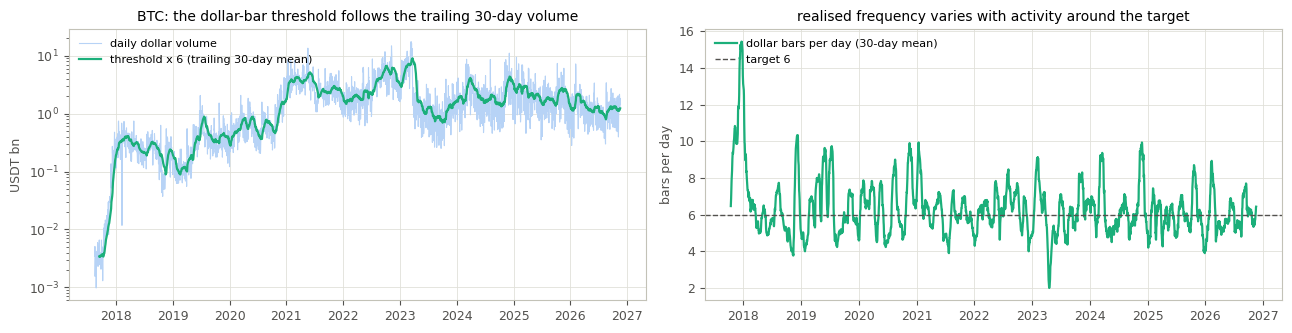

In [3]:
# the threshold rule at work: BTC dollar bars at 6/day — threshold, daily dollar volume and bars per day
if "dollar" in BAR_TYPES:
    b = qd.load_bars(["BTC"], qd.BarConfig("dollar", 6), end=DATA_END, update=False)["BTC"]
    dd = DAILY["BTC"].set_index(pd.DatetimeIndex(DAILY["BTC"]["bar_start"]))
    thr = b["threshold"].resample("D").first()
    npd = b["close"].resample("D").size()
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
    ax[0].plot(dd.index, dd["quote_volume"] / 1e9, color="#b7d3f6", lw=0.8, label="daily dollar volume")
    ax[0].plot(thr.index, thr * 6 / 1e9, color=COL["dollar"], lw=1.6, label="threshold x 6 (trailing 30-day mean)")
    ax[0].set_yscale("log"); ax[0].set_ylabel("USDT bn"); ax[0].legend(fontsize=8, loc="upper left")
    ax[0].set_title("BTC: the dollar-bar threshold follows the trailing 30-day volume")
    ax[1].plot(npd.index, npd.rolling(30).mean(), color=COL["dollar"], label="dollar bars per day (30-day mean)")
    ax[1].axhline(6, color=INK2, ls="--", lw=1, label="target 6")
    ax[1].set_ylabel("bars per day"); ax[1].legend(fontsize=8, loc="upper left")
    ax[1].set_title("realised frequency varies with activity around the target")
    fig.tight_layout(); plt.show()

### The per-configuration pipeline

For every configuration the cell below (cached on disk, keyed by a fingerprint of the bars) does the same steps with library
calls: load the bars; record sampling diagnostics (achieved bars per day, bar durations, segments, empty klines, bars closed by
an outage gap, two strategy-specific diagnostics explained in §4); compute the elapsed-time features
(`qf.elapsed_bar_features`: per-asset families V, T, F, CAL in calendar time, and M, R, X from the other assets' latest bars at
or before each decision time); run the four strategies on the 40 assets and keep the closed trades with the features of their
signal bar (`ml.build_trade_panel`, 5 bps per fill, no slippage).

In [4]:
DAY_US = 86_400 * 10 ** 6
CONFIG_CACHE = DiskCache(CACHE_ROOT / "configs", key={"data_end": str(DATA_END), "fee": FEE_BPS, "strategies": SS,
                                                       "features": "elapsed-v1", "quant_forge": quant_forge.__version__})


def tis_daily_candle_coverage(bars, tolerance_h=1.5):
    # share of UTC days (first to last bar) whose daily candle passes the coverage rule of quant_forge.strategies.htf:
    # bars grouped by their END; the first one started <= day start + tolerance, the last one ended >= day end - tolerance
    tol = int(tolerance_h * 3600 * 10 ** 6)
    out = {}
    for a, b in bars.items():
        s, e = b["bar_start_us"].to_numpy(np.int64), b["bar_end_us"].to_numpy(np.int64)
        day = (e - 1) // DAY_US
        first, last = np.r_[True, day[1:] != day[:-1]], np.r_[day[1:] != day[:-1], True]
        d0 = day[first] * DAY_US
        out[a] = float(((s[first] <= d0 + tol) & (e[last] >= d0 + DAY_US - tol)).sum() / (day[-1] - day[0] + 1))
    return pd.Series(out)


def build_config(cfg):
    t = time.time()
    bars = qd.load_bars(ALL_ASSETS, cfg, end=DATA_END, update=False)
    name = f"{cfg.key}_{frame_fingerprint(bars, columns=['open', 'high', 'low', 'close', 'volume'])}"
    if name in CONFIG_CACHE:
        return CONFIG_CACHE.load(name)
    durs = np.concatenate([qd.bar_durations(b).dropna().to_numpy() for b in bars.values()])
    info = {"summary": qd.sampling_summary(bars, cfg.bars_per_day),
            "yearly": qd.sampling_by_period(bars, "YS"), "monthly": qd.sampling_by_period(bars, "MS"),
            "dur_hist": np.histogram(np.log2(durs[durs > 0] / cfg.nominal_hours), bins=np.arange(-10, 8.01, 0.125))[0],
            "tis_htf_complete": tis_daily_candle_coverage(bars),
            "vol_filter_pass": pd.Series({a: float((b["volume"] > b["volume"].rolling(20).mean()).mean()) for a, b in bars.items()}),
            "empty_bars": pd.Series({a: int((b["complete"] == 0).sum()) for a, b in bars.items()}),
            "gap_closed": pd.Series({a: int((b["closed_by"] == "gap").sum()) if "closed_by" in b else 0 for a, b in bars.items()}),
            "n_bars": pd.Series({a: len(b) for a, b in bars.items()})}
    feats = qf.elapsed_bar_features(bars, n_jobs=N_JOBS)
    feats = {a: f.astype({c: np.float32 for c in f.columns if c != "raw_close"}) for a, f in feats.items()}
    cols = qf.model_columns(feats["BTC"])
    trades = ml.build_trade_panel(bars, feats, STRATEGIES, feature_columns=cols, tick_sizes=qd.TICK_SIZES,
                                  fee_bps=FEE_BPS, slippage_ticks=0, n_jobs=N_JOBS)
    del bars, feats
    gc.collect()
    trades["group"] = ml.assign_groups(trades, {"SEEN": SEEN, "NEW": NEW})
    trades["month"] = trades["exit_time"].dt.strftime("%Y-%m")
    out = {"trades": trades, "info": info, "seconds": time.time() - t}
    CONFIG_CACHE.save(name, out)
    return out


TRADES, INFO = {}, {}
for cfg in CONFIGS:
    t = time.time()
    res_cfg = build_config(cfg)
    TRADES[cfg.key], INFO[cfg.key] = res_cfg["trades"], res_cfg["info"]
    print(f"{cfg.label:12s} bars {int(INFO[cfg.key]['n_bars'].sum()):>10,}  closed trades {len(TRADES[cfg.key]):>7,}  "
          f"({time.time() - t:5.0f} s now, {res_cfg['seconds']:5.0f} s when computed)")
    del res_cfg
    gc.collect()

time 30m     bars  5,084,058  closed trades 158,539  (    3 s now,   213 s when computed)


time 1h      bars  2,542,224  closed trades  82,625  (    1 s now,   107 s when computed)


time 4h      bars    635,908  closed trades  22,389  (    1 s now,    25 s when computed)


time 1d      bars    106,021  closed trades   5,158  (    0 s now,    10 s when computed)


volume 48/d  bars  5,297,656  closed trades 145,645  (    4 s now,   153 s when computed)


volume 24/d  bars  2,675,261  closed trades  74,900  (    2 s now,    70 s when computed)


... (2 outputs left out)

dollar 48/d  bars  5,443,536  closed trades 151,758  (    4 s now,   161 s when computed)


dollar 24/d  bars  2,749,835  closed trades  75,444  (    2 s now,    76 s when computed)


dollar 6/d   bars    693,506  closed trades  18,142  (    1 s now,    23 s when computed)


dollar 1/d   bars    115,927  closed trades   3,170  (    1 s now,     8 s when computed)


## 3. Sampling frequency: how closely does each configuration match its target?

Achieved bars per day are counted per asset over the days on which the asset had bars; a bar's duration is the time since the
previous bar's end in the same segment (the sampling interval). For time bars both are fixed by construction, except for
missing klines and klines without trades (which become segment breaks). For volume and dollar bars both follow activity: the
target is met only on average, and only to the extent that the trailing 30-day volume predicts the next day's volume.

In [5]:
rows = []
for k in KEYS:
    cfg, inf = CFG[k], INFO[k]
    s, y = inf["summary"], inf["yearly"]
    yr = y.loc[y["active days"] > 60, "bars/day"] / cfg.bars_per_day
    rows.append({"config": cfg.label, "bar type": cfg.bar_type, "target /day": cfg.bars_per_day,
                 "achieved /day (median asset)": s["bars/day"].median(),
                 "ratio median": s["ratio to target"].median(), "ratio min asset": s["ratio to target"].min(),
                 "ratio max asset": s["ratio to target"].max(),
                 "asset-year ratio p10": yr.quantile(0.1), "asset-year ratio p90": yr.quantile(0.9),
                 "nominal h": cfg.nominal_hours, "dur p05 h": s["dur p05 (h)"].median(), "dur p50 h": s["dur p50 (h)"].median(),
                 "dur p95 h": s["dur p95 (h)"].median(), "share > 4x nominal": s["share > 4x nominal"].median(),
                 "segments / asset": s["segments"].median(), "empty klines (all)": int(inf["empty_bars"].sum()),
                 "gap-closed bars (all)": int(inf["gap_closed"].sum())})
SAMPLING = pd.DataFrame(rows).set_index("config")
SAMPLING["freq flag"] = ~SAMPLING["ratio median"].between(*FREQ_RATIO_BAND)
print("Achieved frequency and bar durations (medians across the 40 assets unless stated):")
display(SAMPLING.round(3))

Achieved frequency and bar durations (medians across the 40 assets unless stated):


,bar type,target /day,achieved /day (median asset),ratio median,ratio min asset,ratio max asset,asset-year ratio p10,asset-year ratio p90,nominal h,dur p05 h,dur p50 h,dur p95 h,share > 4x nominal,segments / asset,empty klines (all),gap-closed bars (all),freq flag
config,,,,,,,,,,,,,,,,,
time 30m,time,48,47.964,0.999,0.998,1.000,0.997,1.000,0.5,0.500,0.500,0.500,0.000,33.0,901,0,False
time 1h,time,24,23.984,0.999,0.998,1.000,0.997,1.000,1.0,1.000,1.000,1.000,0.000,22.5,119,0,False
time 4h,time,6,5.999,1.000,0.999,1.000,0.998,1.001,4.0,4.000,4.000,4.000,0.000,3.0,0,0,False
time 1d,time,1,1.000,1.000,1.000,1.000,0.997,1.003,24.0,24.000,24.000,24.000,0.000,1.0,0,0,False
volume 48/d,volume,48,49.912,1.040,1.011,1.096,0.967,1.127,0.5,0.015,0.339,1.417,0.014,6.0,0,225,False
volume 24/d,volume,24,25.126,1.047,1.023,1.109,0.976,1.141,1.0,0.041,0.714,2.659,0.009,6.0,0,225,False
volume 6/d,volume,6,6.320,1.053,1.028,1.121,0.982,1.155,4.0,0.278,3.149,9.463,0.003,6.0,0,224,False
volume 1/d,volume,1,1.058,1.058,1.029,1.126,0.981,1.162,24.0,3.092,20.707,49.025,0.001,6.0,0,225,False
dollar 48/d,dollar,48,51.265,1.068,1.020,1.197,0.921,1.207,0.5,0.013,0.312,1.468,0.017,6.0,0,225,False


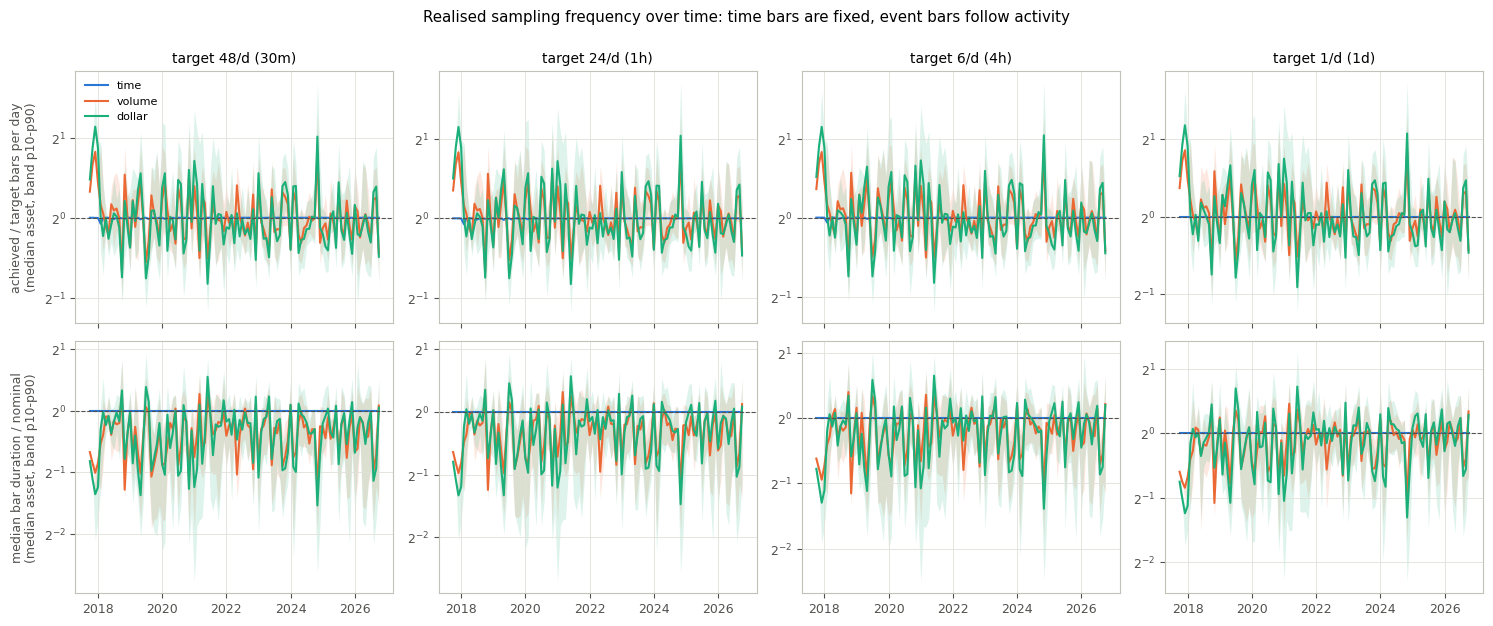

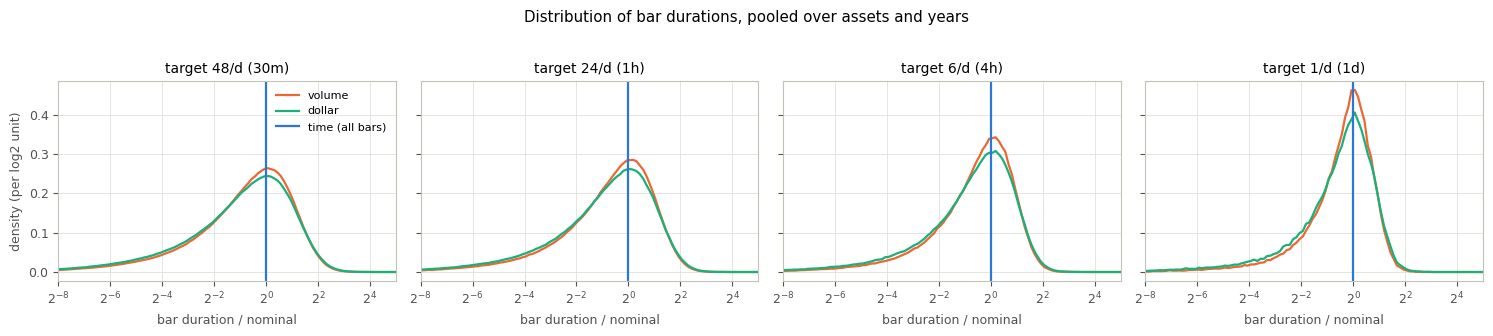

Achieved / target bars per day by asset (event bars), whole history of each asset:


,count,mean,std,min,10%,50%,90%,max
volume 48/d,40.0,1.041,0.019,1.011,1.018,1.040,1.066,1.096
volume 24/d,40.0,1.052,0.020,1.023,1.027,1.047,1.078,1.109
volume 6/d,40.0,1.060,0.023,1.028,1.034,1.053,1.092,1.121
volume 1/d,40.0,1.064,0.024,1.029,1.037,1.058,1.098,1.126
dollar 48/d,40.0,1.070,0.034,1.020,1.029,1.068,1.106,1.197
dollar 24/d,40.0,1.081,0.036,1.029,1.042,1.075,1.125,1.213
dollar 6/d,40.0,1.090,0.039,1.033,1.054,1.084,1.142,1.230
dollar 1/d,40.0,1.094,0.040,1.035,1.056,1.086,1.145,1.235


Assets furthest from the target (dollar 6/d): {'DOT': 1.033, 'GRT': 1.036, 'ICP': 1.044, 'HBAR': 1.144, 'MANA': 1.155, 'DOGE': 1.23}


In [6]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharex=True)
for j, n in enumerate(FREQS):
    for bt in BAR_TYPES:
        cfg = qd.BarConfig(bt, n)
        m = INFO[cfg.key]["monthly"]
        m = m.loc[m["active days"] >= 20].copy()
        m["ratio"] = m["bars/day"] / n
        m["dur_rel"] = m["dur p50 (h)"] / cfg.nominal_hours
        for i, col in enumerate(["ratio", "dur_rel"]):
            g = m.groupby("period")[col]
            med, lo, hi = g.median(), g.quantile(0.1), g.quantile(0.9)
            ax = axes[i, j]
            ax.plot(med.index, med, color=COL[bt], label=bt, lw=1.5)
            if bt != "time":
                ax.fill_between(med.index, lo, hi, color=COL[bt], alpha=0.15, lw=0)
    for i in range(2):
        axes[i, j].axhline(1, color=INK2, ls="--", lw=0.8)
        axes[i, j].set_yscale("log", base=2)
    axes[0, j].set_title(f"target {FREQ_LABEL[n]}")
import matplotlib.dates as mdates
for ax in axes.ravel():
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0, 0].set_ylabel("achieved / target bars per day\n(median asset, band p10-p90)")
axes[1, 0].set_ylabel("median bar duration / nominal\n(median asset, band p10-p90)")
axes[0, 0].legend(fontsize=8, loc="upper left")
fig.suptitle("Realised sampling frequency over time: time bars are fixed, event bars follow activity", y=1.0)
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
centers = np.arange(-10, 8, 0.125) + 0.0625
for j, n in enumerate(FREQS):
    ax = axes[j]
    for bt in [b_ for b_ in ["volume", "dollar"] if b_ in BAR_TYPES]:
        h = INFO[qd.BarConfig(bt, n).key]["dur_hist"]
        ax.plot(2.0 ** centers, h / h.sum() / 0.125, color=COL[bt], label=bt)
    ax.axvline(1, color=COL["time"], lw=1.6, label="time (all bars)")
    ax.set_xscale("log", base=2); ax.set_xlim(2 ** -8, 2 ** 5)
    ax.set_title(f"target {FREQ_LABEL[n]}"); ax.set_xlabel("bar duration / nominal")
axes[0].set_ylabel("density (per log2 unit)"); axes[0].legend(fontsize=8)
fig.suptitle("Distribution of bar durations, pooled over assets and years", y=1.03)
fig.tight_layout(); plt.show()

per_asset = pd.DataFrame({CFG[k].label: INFO[k]["summary"]["ratio to target"] for k in KEYS if CFG[k].bar_type != "time"})
if not per_asset.empty:
    print("Achieved / target bars per day by asset (event bars), whole history of each asset:")
    display(per_asset.describe(percentiles=[0.1, 0.5, 0.9]).T.round(3))
    print("Assets furthest from the target (dollar 6/d):",
          per_asset["dollar 6/d"].sort_values().iloc[[0, 1, 2, -3, -2, -1]].round(3).to_dict())

## 4. The primary strategies on every configuration

Same rules and default parameters everywhere; only the bars change. Indicator lengths are in bars, so a 200-bar EMA spans
100 hours on 30-minute bars and 200 days on daily bars, and Donchian's 20-bar maximum hold is 10 hours or 20 days: that is what
"changing the sampling frequency of a strategy" means. None of the four strategies reads another asset's bars in its rules
(TIS is named after BTC but trades each asset on its own bars and its own daily candles); BTC and cross-asset information enter
only through the meta-model's M, R and X features, which are aligned as-of across asynchronous bars (§5). Two rules interact
with the bar type beyond their length:

* **TIS** confirms with green *daily* candles rebuilt from its input bars (`htf = "1D"`), and a daily candle only counts when
  the bars ending in that day cover it within 1.5 hours of both boundaries. Event bars do not respect day boundaries; the
  share of days that pass this rule is shown below (`TIS daily candle complete`), and on daily event bars it collapses.
* **SuperTrend** requires the flip bar's volume to exceed its 20-bar mean. On volume bars every bar carries about the threshold
  volume, so the filter passes about half of the bars, decided by the overshoot of the closing trade rather than by activity;
  on dollar bars it reacts to price moves (base volume per dollar falls when the price rises). Shown as `volume filter pass`.

Counts below are closed trades decided in the evaluation period (2019-03-01 → 2026-11-19).

In [7]:
def eval_trades(k):
    tr = TRADES[k]
    return tr.loc[(tr["decision_time"] >= EVAL_START) & (tr["decision_time"] < DATA_END)]


rows = []
for k in KEYS:
    ev = eval_trades(k)
    for (s, g), x in ev.groupby(["strategy", "group"]):
        asset_years = sum(((DATA_END - max(EVAL_START, INFO[k]["summary"].loc[a, "first bar"])).days / 365.25)
                          for a in (SEEN if g == "SEEN" else NEW))
        rows.append({"config": CFG[k].label, "bar type": CFG[k].bar_type, "freq": CFG[k].bars_per_day, "strategy": s,
                     "group": g, "trades": len(x), "trades / asset-year": len(x) / asset_years,
                     "win rate": x["y"].mean(), "mean net bps": 1e4 * x["trade_return"].mean(),
                     "mean gross bps": 1e4 * x["trade_return_gross"].mean(), "median hold h": x["holding_hours"].median(),
                     "p90 hold h": x["holding_hours"].quantile(0.9), "short share": (x["side"] < 0).mean()})
PRIMARY = pd.DataFrame(rows)
cnt = PRIMARY.pivot_table(index=["group", "strategy"], columns="config", values="trades", sort=False)[[CFG[k].label for k in KEYS]]
print("Closed trades in the evaluation period by group, strategy and configuration:")
display(cnt.astype(int))
print("Per-trade statistics on NEW assets (net of 5 bps per fill):")
display(PRIMARY.loc[PRIMARY["group"].eq("NEW")].set_index(["strategy", "bar type", "freq"]).sort_index()
        [["trades", "trades / asset-year", "win rate", "mean gross bps", "mean net bps", "median hold h", "p90 hold h"]].round(3))

diag = pd.DataFrame({CFG[k].label: {"TIS daily candle complete (median asset)": INFO[k]["tis_htf_complete"].median(),
                                    "TIS daily candle complete (worst asset)": INFO[k]["tis_htf_complete"].min(),
                                    "volume filter pass (median asset)": INFO[k]["vol_filter_pass"].median()} for k in KEYS})
print("Strategy-specific consequences of the bar type:")
display(diag.round(3))

Closed trades in the evaluation period by group, strategy and configuration:


config            time 30m  time 1h  time 4h  time 1d  volume 48/d  volume 24/d  volume 6/d  volume 1/d  dollar 48/d  dollar 24/d  dollar 6/d  dollar 1/d
group strategy                                                                                                                                           
NEW   DONCHIAN       12753     6193     1569      260        14815         7256        1706         280        15255         7427        1791         294
      RSI            29817    15675     4286      816        32061        16328        4266         876        33077        16940        4449         953
      SUPERTREND     24968    12890     2938      399        14074         8147        2887         310        14537         7377        1751         264
      TIS             5641     3331     1350      838         8087         3331         209           1         9562         3999         362           2
SEEN  DONCHIAN       13909     6930     1771      357        15493         7778        1987         308        15828         8071        2036         341
      RSI            32797    17335     4868      959        34536        17940        4918         954        35640        18537        5205        1016
      SUPERTREND     27137    13836     3436      470        13506         8173        2890         324        13646         6791        1638         222
      TIS             5861     3440     1384      923         7730         3139         195           3         9035         3697         289           4

Per-trade statistics on NEW assets (net of 5 bps per fill):


trades  trades / asset-year  win rate  mean gross bps  mean net bps  median hold h  p90 hold h
strategy   bar type freq                                                                                                
DONCHIAN   dollar   1        294                2.132     0.602         712.648       702.291        165.108     437.192
                    6       1791               12.983     0.513          68.228        58.194         21.563      65.374
                    24      7427               53.838     0.490           0.574        -9.426          6.545      21.818
                    48     15255              110.582     0.478          -6.416       -16.413          3.409      12.779
           time     1        260                1.885     0.538        1838.864      1827.945        480.000     480.000
                    6       1569               11.374     0.479         194.018       183.921         80.000      80.000
                    24      6193               44.892     0.463          35.666        25.648         20.000      20.000
                    48     12753               92.445     0.436          -2.754       -12.752         10.000      10.000
           volume   1        280                2.031     0.586        1112.305      1101.749        279.903     532.410
                    6       1706               12.367     0.516         102.316        92.265         31.349      77.323
                    24      7256               52.598     0.490           4.738        -5.264          8.825      23.524
                    48     14815              107.392     0.484          -6.449       -16.446          4.502      13.617
RSI        dollar   1        953                6.912     0.319          57.142        47.113          7.895      33.547
                    6       4449               32.251     0.313          -6.208       -16.205          1.078       6.664
                    24     16940              122.796     0.299          -6.803       -16.800          0.314       2.188
                    48     33077              239.772     0.302          -2.552       -12.551          0.179       1.232
           time     1        816                5.915     0.324         438.223       428.003         48.000     204.000
                    6       4286               31.069     0.259           1.988        -8.013          8.000      28.000
                    24     15675              113.626     0.258         -13.071       -23.065          2.000       7.000
                    48     29817              216.140     0.249         -12.322       -22.316          1.000       3.500
           volume   1        876                6.353     0.316         129.893       119.829         14.266      64.685
                    6       4266               30.924     0.292         -14.272       -24.264          1.639       8.524
                    24     16328              118.360     0.298          -6.026       -16.023          0.433       2.581
                    48     32061              232.407     0.298          -4.587       -14.584          0.231       1.362
SUPERTREND dollar   1        264                1.915     0.337        -885.649      -896.212       1131.940    9053.908
                    6       1751               12.693     0.316        -210.113      -220.248        118.312    1686.097
                    24      7377               53.475     0.330         -61.474       -71.507         39.714     341.111
                    48     14537              105.377     0.332         -46.107       -56.125         22.422     162.024
           time     1        399                2.892     0.421         496.159       485.701       1272.000    4156.800
                    6       2938               21.297     0.392         106.960        96.931        208.000     693.200
                    24     12890               93.438     0.352          -1.443       -11.451         51.000     158.000
                    48     24968 

Strategy-specific consequences of the bar type:


,time 30m,time 1h,time 4h,time 1d,volume 48/d,volume 24/d,volume 6/d,volume 1/d,dollar 48/d,dollar 24/d,dollar 6/d,dollar 1/d
TIS daily candle complete (median asset),1.000,1.000,1.000,1.000,0.934,0.759,0.285,0.052,0.924,0.738,0.286,0.054
TIS daily candle complete (worst asset),0.999,0.999,0.999,1.000,0.872,0.689,0.259,0.043,0.853,0.668,0.258,0.043
volume filter pass (median asset),0.361,0.361,0.374,0.379,0.282,0.348,0.559,0.552,0.390,0.447,0.501,0.519


### Reproduction check: the 4h time-bar baseline gives the reference signals

The reference notebook built its trades with `qf.bar_features(bars, bars_per_day=6)` (bar-count features) and
`ml.build_trade_panel`. Trades depend only on the bars and the strategy rules, so the 4h time-bar configuration of this
notebook — loaded through the new `qd.load_bars` interface and carrying the new elapsed-time features — must produce exactly the
same signals, entries, exits and returns. The cell rebuilds the reference trade table with the reference calls on the common
history (the whole reference period, first bar 2017-09-16 → 2026-11-19), compares it trade by trade, and compares the counts
with the output stored in the reference notebook.

In [8]:
bars4 = qd.load_binance_bars(ALL_ASSETS, end=DATA_END, interval="4h", warmup_days=30)
ref_feats = qf.add_raw_levels(qf.bar_features(bars4, bars_per_day=6, btc="BTC"), bars4)
ref_trades = ml.build_trade_panel(bars4, ref_feats, STRATEGIES, feature_columns=["raw_close", "v_rvol_30d"],
                                  tick_sizes=qd.TICK_SIZES, fee_bps=FEE_BPS, slippage_ticks=0, n_jobs=N_JOBS)
del ref_feats, bars4
gc.collect()
KEYCOLS = ["strategy", "asset", "side", "decision_time", "entry_time", "exit_time", "entry_price", "trade_return", "exit_reason"]
a = ref_trades[KEYCOLS].sort_values(KEYCOLS[:4]).reset_index(drop=True)
bb = TRADES[BASELINE].sort_values(KEYCOLS[:4]).reset_index(drop=True)
b = bb[KEYCOLS]
identical = a.equals(b)
print(f"reference pipeline: {len(a):,} closed trades; this notebook's time 4h: {len(b):,}; identical trade by trade: {identical}")

ref_nb = json.loads((ROOT / "research/meta-labeling/meta_labeling_economic_value_quant_forge.ipynb").read_text())
stored = None
for cell in ref_nb["cells"]:
    for o in cell.get("outputs", []):
        txt = "".join(o.get("text", ""))
        m_ = re.search(r"([\d,]+) closed trades", txt)
        if m_:
            stored = int(m_.group(1).replace(",", ""))
print(f"closed trades printed by the reference notebook: {stored:,} -> match: {stored == len(b)}")
period = ml.assign_periods(bb["decision_time"], [("A", pd.Timestamp("2021-09-01", tz="UTC")),
                                                  ("B", pd.Timestamp("2026-09-01", tz="UTC"))], last="C")
print("Same layout as the reference notebook's count table (group x strategy x period):")
display(pd.crosstab([bb["group"], bb["strategy"]], period, margins=True, margins_name="total"))
assert identical and stored == len(b)

reference pipeline: 22,389 closed trades; this notebook's time 4h: 22,389; identical trade by trade: True
closed trades printed by the reference notebook: 22,389 -> match: True
Same layout as the reference notebook's count table (group x strategy x period):


col_0                A      B    C  total
group strategy                           
NEW   DONCHIAN     465   1072   50   1587
      RSI         1286   2944  119   4349
      SUPERTREND   691   2202   82   2975
      TIS          370    950   41   1361
SEEN  DONCHIAN     637   1186   46   1869
      RSI         1824   3252  119   5195
      SUPERTREND   978   2502  113   3593
      TIS          433    986   41   1460
total             6684  15094  611  22389

## 5. Meta-labeling with one specification for every configuration

* **Label**: `y = 1[net trade return > 0]` of the primary trade (AFML §3.6); the primary strategy fixes side and exit.
* **Candidates** (fixed list, the same for every configuration): the elapsed-time families V, T, F, CAL, M, R, X of the signal
  bar, the strategy's own features (LIB; price levels as ratios to the signal close), the track record S (trades closed
  strictly before the decision; open positions and signals in the last 24 hours), with direction-carrying features multiplied
  by the trade side (`ml.prepare_meta_dataset`). Features missing on more than 30 % of a window's training trades are dropped.
* **Model**: logistic regression on median-imputed, normal-quantile-transformed features; `C ∈ {0.003, 0.01, 0.03, 0.1, 0.3}`
  chosen by the inner purged K-fold on common calendar folds (4 folds, purge by decision-to-exit overlap, 1 % embargo, log-loss
  scoring); Platt calibration on the inner out-of-fold probabilities; sizing constants (break-even win rate `p_be` from the
  training payouts, median training volatility, rule normalisations) from the same training trades
  (`ml.fit_window` with `MetaLabelingConfig(model_names=("LR",), pca_models=(), feature_selection=False)`).
* **Walk-forward**: 12-month windows from 2019-03-01; training = `SEEN` trades that **exited** before the window start (at least
  200); predictions for the window's trades on both groups.
* **Windows without a model** (fewer than 200 training trades): their trades stay in the evaluation and the rules fall back to
  inverse volatility (no filter, no probability sizing) — a practitioner cannot meta-label before having trades. The share of
  evaluated trades covered by a model is reported and flagged.

In [9]:
from quant_forge.validation.calendar_kfold import to_int64_ns

DS, RES, PRED = {}, {}, {}
for k in KEYS:
    t = time.time()
    ds = ml.prepare_meta_dataset(TRADES[k])
    cands = {s: ds.candidates_for(s) for s in SS}
    cache = DiskCache(CACHE_ROOT / "walk_forward", key={
        "bar": k, "config": MLCFG.cache_key(), "windows": [str(w) for w in WINDOWS], "candidates": cands,
        "trades": frame_fingerprint(ds.trades[["strategy", "asset", "decision_time", "exit_time", "trade_return"]])})
    res = ml.run_walk_forward(ds.trades, SS, WINDOWS, cands, MLCFG, cache=cache, n_jobs=WF_JOBS, inner_n_jobs=1, verbose=False)
    PRED[k] = ml.collect_predictions(res, ds.trades, ["strategy", "asset", "group", "decision_time", "entry_time", "exit_time",
                                                      "trade_return", "y", "v_rvol_30d", "month"]) if res else pd.DataFrame()
    DS[k], RES[k] = ds, res
    TRADES[k] = ds.trades
    print(f"{CFG[k].label:12s} {len(res):2d} of {len(SS) * len(WINDOWS)} (strategy, window) fits, "
          f"{len(PRED[k]):>7,} outer predictions, candidates per strategy {[len(c) for c in cands.values()]} ({time.time() - t:4.0f} s)")
FAMILY = DS[BASELINE].family
print("candidate features by family (time 4h, RSI):",
      pd.Series([FAMILY[c] for c in DS[BASELINE].candidates_for("RSI")]).value_counts().reindex(list(qf.FAMILY_ORDER)).fillna(0).astype(int).to_dict())

time 30m     32 of 32 (strategy, window) fits, 152,883 outer predictions, candidates per strategy [65, 76, 69, 75] (   1 s)


time 1h      31 of 32 (strategy, window) fits,  79,206 outer predictions, candidates per strategy [65, 76, 69, 75] (   1 s)


time 4h      28 of 32 (strategy, window) fits,  20,465 outer predictions, candidates per strategy [65, 76, 69, 75] (   0 s)


time 1d      18 of 32 (strategy, window) fits,   3,187 outer predictions, candidates per strategy [65, 76, 69, 75] (   0 s)


volume 48/d  32 of 32 (strategy, window) fits, 140,302 outer predictions, candidates per strategy [65, 76, 69, 75] (   1 s)


volume 24/d  32 of 32 (strategy, window) fits,  72,092 outer predictions, candidates per strategy [65, 76, 69, 75] (   1 s)


... (2 outputs left out)

dollar 48/d  32 of 32 (strategy, window) fits, 146,580 outer predictions, candidates per strategy [65, 76, 69, 75] (   1 s)


dollar 24/d  32 of 32 (strategy, window) fits,  72,839 outer predictions, candidates per strategy [65, 76, 69, 75] (   1 s)


dollar 6/d   25 of 32 (strategy, window) fits,  16,469 outer predictions, candidates per strategy [65, 76, 69, 75] (   0 s)


dollar 1/d   10 of 32 (strategy, window) fits,   1,635 outer predictions, candidates per strategy [65, 76, 69, 75] (   0 s)
candidate features by family (time 4h, RSI): {'LIB': 1, 'FFD': 0, 'V': 7, 'T': 15, 'F': 7, 'CAL': 5, 'M': 14, 'R': 3, 'X': 3, 'S': 10}


In [10]:
rows = []
for k in KEYS:
    tr = TRADES[k]
    ev = tr.loc[(tr["decision_time"] >= EVAL_START) & (tr["decision_time"] < DATA_END)]
    covered = set(PRED[k]["row"]) if len(PRED[k]) else set()
    for s in SS:
        fits = {w0: r.diagnostics for (ss, w0), r in RES[k].items() if ss == s}
        e = ev.loc[ev["strategy"].eq(s)]
        rows.append({"config": CFG[k].label, "strategy": s, "windows fitted": len(fits),
                     "first fitted window": min(fits).date() if fits else None,
                     "median training trades": np.median([d["n_train"] for d in fits.values()]) if fits else 0,
                     "usable features (median)": np.median([d["n_usable"] for d in fits.values()]) if fits else 0,
                     "C (most frequent)": pd.Series([d["tuning"]["LR-FULL"]["params"]["C"] for d in fits.values()]).mode().iloc[0] if fits else None,
                     "inner ll − prior (mean)": np.mean([d["tuning"]["LR-FULL"]["inner_ll"] - d["prior_inner_ll"] for d in fits.values()]) if fits else np.nan,
                     "model coverage (all)": e.index.isin(covered).mean() if len(e) else np.nan,
                     "model coverage (NEW)": e.loc[e["group"].eq("NEW")].index.isin(covered).mean() if len(e) else np.nan})
COVERAGE = pd.DataFrame(rows).set_index(["strategy", "config"]).sort_index(level=0, sort_remaining=False)
print("Walk-forward fits and model coverage of the evaluated trades:")
display(COVERAGE.round(4))
c_all = [d.diagnostics["tuning"]["LR-FULL"]["params"]["C"] for k in KEYS for d in RES[k].values()]
ll_all = [d.diagnostics["tuning"]["LR-FULL"]["inner_ll"] - d.diagnostics["prior_inner_ll"] for k in KEYS for d in RES[k].values()]
from quant_forge import models as qm
grid_min = min(p_["C"] for p_ in qm.lr_spec().grid)
print(f"{len(c_all)} fitted windows: the smallest C of the grid ({grid_min}) was chosen in {np.mean(np.isclose(c_all, grid_min)):.0%}; "
      f"the inner log loss beat the training prior in {np.mean(np.array(ll_all) < 0):.0%} of them")

Walk-forward fits and model coverage of the evaluated trades:


windows fitted first fitted window  median training trades  usable features (median)  C (most frequent)  inner ll − prior (mean)  model coverage (all)  model coverage (NEW)
strategy   config                                                                                                                                                                                   
DONCHIAN   time 30m                  8          2019-03-01                  6381.0                      75.0              0.003                   0.0033                1.0000                1.0000
           time 1h                   8          2019-03-01                  3200.0                      75.0              0.003                   0.0013                1.0000                1.0000
           time 4h                   7          2020-03-01                   943.0                      74.0              0.003                   0.0017                0.9293                0.9420
           time 1d                   3          2024-03-01                   304.0                      71.0              0.003                   0.0483                0.3079                0.2923
           volume 48/d               8          2019-03-01                  7210.5                      75.0              0.003                   0.0054                1.0000                1.0000
           volume 24/d               8          2019-03-01                  3688.0                      75.0              0.003                   0.0086                1.0000                1.0000
           volume 6/d                7          2020-03-01                  1058.0                      75.0              0.003                   0.0019                0.9101                0.9185
           volume 1/d                3          2024-03-01                   262.0                      73.0              0.003                   0.0358                0.3571                0.3429
           dollar 48/d               8          2019-03-01                  7566.5                      75.0              0.003                   0.0026                1.0000                1.0000
           dollar 24/d               8          2019-03-01                  3917.0                      75.0              0.003                   0.0025                1.0000                1.0000
           dollar 6/d                7          2020-03-01                  1094.0                      75.0              0.003                  -0.0032                0.9072                0.9129
           dollar 1/d                3          2024-03-01                   296.0                      73.0              0.003                   0.0165                0.3638                0.3707
RSI        time 30m                  8          2019-03-01                 15597.5                      65.0              0.003                   0.0048                1.0000                1.0000
           time 1h                   8          2019-03-01                  8359.0                      65.0              0.003                   0.0032                1.0000                1.0000
           time 4h                   8          2019-03-01                  2443.5                      65.0              0.003                   0.0029                1.0000                1.0000
           time 1d                   6          2021-03-01                   624.5                      62.0              0.003                   0.0237                0.7161                0.7390
           volume 48/d               8          2019-03-01                 16503.0                      65.0              0.003                   0.0028                1.0000                1.0000
           volume 24/d               8          2019-03-01                  8637.5                      65.0              0.003                   0.0025                1.0000                1.0000
           volume 6/d                8          2019-03-01                  2518.5  

305 fitted windows: the smallest C of the grid (0.003) was chosen in 99%; the inner log loss beat the training prior in 29% of them


In [11]:
rows = []
for k in KEYS:
    p = PRED[k]
    if not len(p):
        continue
    for (s, g), x in p.groupby(["strategy", "group"]):
        if len(x) < 50 or x["y"].nunique() < 2:
            continue
        dl, lo, hi = qe.delta_log_loss_ci(x, "p", n_boot=N_BOOT, seed=SEED)
        rows.append({"group": g, "strategy": s, "config": CFG[k].label, "n": len(x), "win rate": x["y"].mean(),
                     "prior (mean)": x["prior"].mean(), "AUC": qe.auc_safe(x["y"], x["p"]), "Δ log loss": dl, "CI low": lo,
                     "CI high": hi, "IC(label)": qe.information_coefficient(x, target="y"),
                     "IC(return)": qe.information_coefficient(x)})
PROBQ = pd.DataFrame(rows).set_index(["group", "strategy", "config"])
print("Outer (walk-forward) probability quality of the meta-model; Δ log loss < 0 = better than the training win rate:")
for g in GROUPS:
    tab = PROBQ.loc[g]
    print(f"\n{g}: AUC by strategy and configuration")
    display(tab["AUC"].unstack("config").reindex(columns=[CFG[k].label for k in KEYS]).round(3))
    print(f"{g}: Δ log loss vs prior (negative = better); cells whose 95 % CI lies below 0: {int((tab['CI high'] < 0).sum())} of {len(tab)}")
    display(tab["Δ log loss"].unstack("config").reindex(columns=[CFG[k].label for k in KEYS]).round(4))

Outer (walk-forward) probability quality of the meta-model; Δ log loss < 0 = better than the training win rate:

NEW: AUC by strategy and configuration


config,time 30m,time 1h,time 4h,time 1d,volume 48/d,volume 24/d,volume 6/d,volume 1/d,dollar 48/d,dollar 24/d,dollar 6/d,dollar 1/d
strategy,,,,,,,,,,,,
DONCHIAN,0.515,0.522,0.510,0.527,0.518,0.520,0.517,0.628,0.515,0.524,0.524,0.409
RSI,0.518,0.516,0.515,0.499,0.498,0.508,0.504,0.534,0.511,0.503,0.500,0.474
SUPERTREND,0.512,0.533,0.549,0.620,0.507,0.500,0.534,0.529,0.496,0.538,0.497,NaN
TIS,0.563,0.543,0.524,0.536,0.577,0.577,NaN,NaN,0.589,0.556,0.521,NaN


NEW: Δ log loss vs prior (negative = better); cells whose 95 % CI lies below 0: 4 of 44


config,time 30m,time 1h,time 4h,time 1d,volume 48/d,volume 24/d,volume 6/d,volume 1/d,dollar 48/d,dollar 24/d,dollar 6/d,dollar 1/d
strategy,,,,,,,,,,,,
DONCHIAN,-0.0001,0.0002,-0.0035,0.0139,-0.0002,-0.0003,0.0031,-0.0061,0.0004,-0.0007,0.0011,0.0198
RSI,0.0002,0.0002,-0.0002,-0.0006,0.0004,0.0007,0.0010,-0.0007,-0.0002,0.0009,0.0001,0.0053
SUPERTREND,-0.0004,-0.0017,-0.0024,-0.0095,0.0001,0.0021,-0.0001,0.0041,0.0008,-0.0002,-0.0013,NaN
TIS,0.0028,-0.0008,-0.0009,0.0018,-0.0062,-0.0060,NaN,NaN,-0.0085,-0.0028,0.0011,NaN



SEEN: AUC by strategy and configuration


config,time 30m,time 1h,time 4h,time 1d,volume 48/d,volume 24/d,volume 6/d,volume 1/d,dollar 48/d,dollar 24/d,dollar 6/d,dollar 1/d
strategy,,,,,,,,,,,,
DONCHIAN,0.521,0.541,0.535,0.505,0.518,0.521,0.559,0.507,0.519,0.521,0.549,0.40
RSI,0.524,0.524,0.522,0.500,0.512,0.513,0.506,0.536,0.508,0.515,0.497,0.45
SUPERTREND,0.521,0.526,0.529,0.551,0.513,0.510,0.564,0.510,0.502,0.542,0.486,NaN
TIS,0.584,0.546,0.537,0.499,0.582,0.579,NaN,NaN,0.567,0.587,0.449,NaN


SEEN: Δ log loss vs prior (negative = better); cells whose 95 % CI lies below 0: 3 of 44


config,time 30m,time 1h,time 4h,time 1d,volume 48/d,volume 24/d,volume 6/d,volume 1/d,dollar 48/d,dollar 24/d,dollar 6/d,dollar 1/d
strategy,,,,,,,,,,,,
DONCHIAN,-0.0003,-0.0015,0.0005,0.0238,-0.0002,-0.0002,-0.0034,0.0137,-0.0006,0.0000,-0.0001,0.0118
RSI,-0.0007,-0.0007,-0.0001,0.0009,-0.0002,-0.0002,0.0003,-0.0038,0.0002,0.0002,0.0020,0.0021
SUPERTREND,-0.0007,-0.0012,-0.0009,-0.0020,-0.0007,0.0005,-0.0066,0.0010,0.0005,-0.0007,-0.0000,NaN
TIS,-0.0064,-0.0014,0.0005,0.0033,-0.0073,-0.0065,NaN,NaN,-0.0053,-0.0079,0.0133,NaN


## 6. Four portfolio rules under one capital budget

| Rule | Size of a signalled trade (notionals of 10 000 USDT) | Question |
|---|---|---|
| **U** | 1 | the primary strategy as it is |
| **D** | `clip(median training vol / vol, 0.25, 4)`, vol = the asset's 30-day realised volatility at the signal | inverse volatility, no model |
| **D×F** | `D × 1[p ≥ p_be]` | what the meta-label filter adds to inverse volatility |
| **D×P** | `D × (2Φ(z) − 1)`, `z = (p − p_be) / sqrt(p (1 − p))`, 0 when `p ≤ p_be` | the same filter plus probability-based sizing (AFML §10.3 centred at the break-even win rate) |

`p` is the calibrated meta-model probability and `p_be = L / (W + L)` the break-even win rate of the strategy's training payouts,
so `D×P` trades exactly the trades that `D×F` trades and only changes their size: **D×F − D is the value of filtering and
D×P − D×F the value of sizing after filtering**.

A filter at `p_be` can add value in two ways: by ranking trades within a window, or simply because the model's average
probability (≈ the training win rate, since the inner cross-validation keeps the logistic regression strongly shrunk) falls
below `p_be` when the strategy lost money in training, which switches the whole strategy off. The diagnostic rule **D×S** does
only the second: `D × 1[training win rate ≥ p_be]` (equivalently, trade a strategy in a window only if its training trades had a
positive mean net return). **D×F − D×S** is then the part of the filter's value that comes from selecting trades. Every rule is divided by its mean on the window's training trades (equal expected
exposure per signal) and capped at 10 notionals.

**Common budget.** Each (configuration, strategy, group) portfolio has the same capital K = 20 notionals (200 000 USDT): one per
asset, so U never needs more (a strategy holds at most one position per asset). Trades are replayed in entry order and cut to
the capital still free (`qz.capital_constrained_sizes`). `ALL` is the four strategy portfolios side by side (4 K).

**Calendar-based measurement.** Every trade is marked to market at each UTC day end with the asset's daily close
(`qe.expand_trade_days`, entry fee on the entry day, exit fee on the exit day; the daily PnL of a trade sums exactly to its net
return), so a strategy that holds for hours and one that holds for months are measured on the same 2 820 days. Sharpe is the
annualised Sharpe of daily PnL (× √365); drawdown is on cumulative daily PnL in units of K; turnover is entry plus exit notional
per year in units of K. Intervals come from one paired monthly block bootstrap (2 000 draws of the 93 calendar months, the same
draws for every series), so two rules or two configurations are always compared on the same resampled months.

In [12]:
CLOSES = qe.daily_close_panel(DAILY, CAL)
WIN_STARTS = np.array([w0.value for w0, _ in WINDOWS], dtype=np.int64)


def portfolio_sizes(k):
    tr = TRADES[k]
    ev = tr.loc[(tr["decision_time"] >= EVAL_START) & (tr["decision_time"] < DATA_END)].copy()
    wi = np.searchsorted(WIN_STARTS, to_int64_ns(ev["decision_time"]), side="right") - 1
    ev["window"] = [WINDOWS[i][0] for i in wi]
    pred = PRED[k].set_index("row") if len(PRED[k]) else pd.DataFrame()
    has = ev.index.isin(pred.index) if len(pred) else np.zeros(len(ev), bool)
    W = pd.DataFrame(np.nan, index=ev.index, columns=EVAL_RULES)
    if has.any():
        sub = pred.loc[ev.index[has]]
        consts = {key: r.diagnostics["constants"] for key, r in RES[k].items()}
        W.loc[sub.index, list(RULES)] = qz.normalized_sizes(sub, consts, cap=SIZE_CAP, rules=tuple(RULES.values()))[list(RULES.values())].to_numpy()
        on = np.array([consts[(s_, w_)].prior >= consts[(s_, w_)].p_be for s_, w_ in zip(sub["strategy"], sub["window"])])
        W.loc[sub.index, "DxS"] = W.loc[sub.index, "D"].to_numpy() * on
        ev.loc[sub.index, "p"] = sub["p"]
        ev.loc[sub.index, "p_be"] = [consts[(s, w)].p_be for s, w in zip(sub["strategy"], sub["window"])]
    for (s, w0), g in ev.loc[~has].groupby(["strategy", "window"]):          # no model yet: inverse volatility only
        vol_tr = tr.loc[tr["strategy"].eq(s) & tr["asset"].isin(SEEN) & (tr["exit_time"] < w0), "v_rvol_30d"].dropna()
        if len(vol_tr) >= 30:
            vm = float(vol_tr.median())
            d = (np.clip(vm / g["v_rvol_30d"], 0.25, 4).fillna(1.0) / float(np.clip(vm / vol_tr, 0.25, 4).mean()))
            d = d.clip(upper=SIZE_CAP).to_numpy()
        else:
            d = np.ones(len(g))
        W.loc[g.index, "U"] = 1.0
        for r in ("D", "DxF", "DxP", "DxS"):
            W.loc[g.index, r] = d
    ev["model"] = has
    Wc = W.copy()
    for _, idx in ev.groupby(["strategy", "group"]).groups.items():
        for r in EVAL_RULES:
            Wc.loc[idx, r] = qz.capital_constrained_sizes(ev.loc[idx, "entry_time"], ev.loc[idx, "exit_time"],
                                                          W.loc[idx, r].to_numpy(), BUDGET, NOTIONAL)
    return ev, W, Wc


def sharpe(x):
    # annualised Sharpe of daily PnL; a portfolio that never trades (all-zero PnL) counts as 0
    x = np.asarray(x, dtype=float)
    sd = x.std(ddof=1)
    if not np.any(x):
        return 0.0
    return float(x.mean() / sd * np.sqrt(365)) if sd > 0 else np.nan


PNL, SIZES, stat_rows = {}, {}, []
G2 = {"NEW": 0, "SEEN": 1}
for k in KEYS:
    ev, W, Wc = portfolio_sizes(k)
    SIZES[k] = (ev, W, Wc)
    code_ = ev["strategy"].map({s: i for i, s in enumerate(SS)}).to_numpy() * 2 + ev["group"].map(G2).to_numpy()
    for fee in (FEE_BPS, FEE_STRESS_BPS):
        td = qe.expand_trade_days(ev, CLOSES, fee_bps=fee, calendar=CAL)
        if fee == FEE_BPS:
            assert np.allclose(td.unit_return(), ev["trade_return"].to_numpy(), atol=1e-9), "mark-to-market != net returns"
        D = qe.daily_pnl(td, Wc[EVAL_RULES].to_numpy().T, notional=NOTIONAL, group=code_, n_groups=2 * len(SS))
        for si, s in enumerate(SS):
            for g, gi in G2.items():
                for ri, r in enumerate(EVAL_RULES):
                    PNL[(fee, g, k, s, r)] = D[si * 2 + gi, ri]
        for g in G2:
            for r in EVAL_RULES:
                PNL[(fee, g, k, "ALL", r)] = np.sum([PNL[(fee, g, k, s, r)] for s in SS], axis=0)
    for g in GROUPS:
        for p in PORTFOLIOS:
            m = ev["group"].eq(g).to_numpy() & (ev["strategy"].eq(p).to_numpy() if p != "ALL" else True)
            K = BUDGET * (len(SS) if p == "ALL" else 1)
            tab = qe.portfolio_table({r: PNL[(FEE_BPS, g, k, p, r)] for r in EVAL_RULES}, budget=K,
                                     trades={r: ev.loc[m] for r in EVAL_RULES}, sizes={r: Wc.loc[m, r].to_numpy() for r in EVAL_RULES},
                                     notional=NOTIONAL)
            for r in EVAL_RULES:
                w_, wc_ = W.loc[m, r].to_numpy(), Wc.loc[m, r].to_numpy()
                stat_rows.append({"group": g, "portfolio": p, "config": k, "rule": r, **tab.loc[r].to_dict(),
                                  "Sharpe 10 bps": sharpe(PNL[(FEE_STRESS_BPS, g, k, p, r)]),
                                  "net PnL 10 bps": PNL[(FEE_STRESS_BPS, g, k, p, r)].sum(),
                                  "signals": int(m.sum()), "model coverage": float(ev.loc[m, "model"].mean()) if m.any() else np.nan,
                                  "share cut by budget": float((wc_ < w_ - 1e-12).mean()) if m.any() else np.nan,
                                  "months with trades": int(ev["month"].iloc[np.flatnonzero(m)[wc_ > 0]].nunique()) if m.any() else 0})
STATS = pd.DataFrame(stat_rows).set_index(["group", "portfolio", "config", "rule"])

BOOT = {}
for fee in (FEE_BPS, FEE_STRESS_BPS):
    for g in GROUPS:
        names = [(k, p, r) for k in KEYS for p in PORTFOLIOS for r in EVAL_RULES]
        B = qe.bootstrap_sharpe(np.vstack([PNL[(fee, g, *n)] for n in names]), MONTHS, n_boot=N_BOOT, seed=SEED)
        for n, b in zip(names, B):
            # flat series (a strategy switched off throughout) -> Sharpe 0 in every draw; otherwise a draw whose
            # resampled months are all flat is also a zero-risk, zero-return portfolio
            BOOT[(fee, g, *n)] = np.where(np.isnan(b), 0.0, b) if not np.any(PNL[(fee, g, *n)]) else b


def delta(g, a, b, fee=FEE_BPS):
    # paired Sharpe difference a - b, a and b = (config, portfolio, rule): (estimate, CI low, CI high, P(Δ > 0))
    d = BOOT[(fee, g, *a)] - BOOT[(fee, g, *b)]
    d = d[np.isfinite(d)]
    est = sharpe(PNL[(fee, g, *a)]) - sharpe(PNL[(fee, g, *b)])
    if not len(d):
        return est, np.nan, np.nan, np.nan
    return est, float(np.quantile(d, 0.025)), float(np.quantile(d, 0.975)), float((d > 0).mean())


def fmt(t):
    est, lo, hi, _ = t
    star = "*" if (lo > 0 or hi < 0) else ""
    return f"{est:+.2f} [{lo:+.2f}, {hi:+.2f}]{star}" if np.isfinite(est) else "n/a"


print(f"{len(PNL) // 2} daily PnL series per fee level on {len(CAL)} days; "
      f"share of trades cut by the budget (NEW, ALL portfolio, median over configurations): "
      + ", ".join(f"{r} {STATS.xs(('NEW', 'ALL', r), level=['group', 'portfolio', 'rule'])['share cut by budget'].median():.3f}" for r in RULES))

600 daily PnL series per fee level on 2820 days; share of trades cut by the budget (NEW, ALL portfolio, median over configurations): U 0.000, D 0.010, DxF 0.021, DxP 0.019


## 7. Results

### 7.1 The primary strategy itself (rule U): which bars and frequencies improve it?

Annualised Sharpe of daily mark-to-market PnL, net of 5 bps per fill, fixed size, budget K = 20 notionals per strategy. Cells
with `*` in the difference tables have a 95 % paired-bootstrap interval that excludes zero.

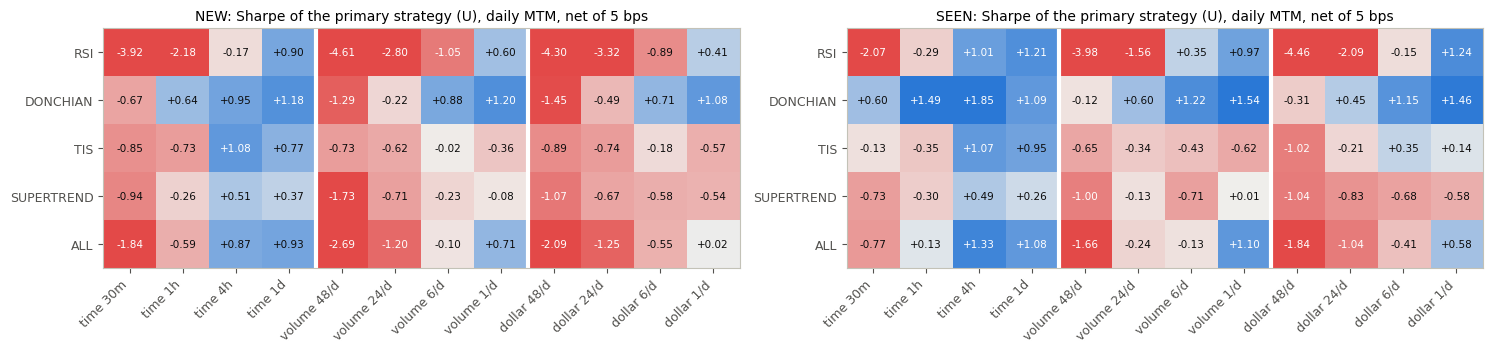

NEW: primary strategy (U) — economics by strategy and configuration


Sharpe  net PnL (kUSD)  return on K (ann.)  max DD / K  turnover (x K / yr)   trades  exposure / K  Sharpe 10 bps
portfolio  config                                                                                                                        
RSI        time 30m     -3.921        -665.387              -0.431      -3.327              385.929  29817.0         0.033         -5.686
           time 1h      -2.185        -361.541              -0.234      -1.855              202.886  15675.0         0.035         -3.132
           time 4h      -0.166         -34.344              -0.022      -0.530               55.475   4286.0         0.037         -0.372
           time 1d       0.903         349.251               0.226      -0.306               10.562    816.0         0.051          0.882
           volume 48/d  -4.614        -467.590              -0.303      -2.345              414.974  32061.0         0.013         -7.629
           volume 24/d  -2.804        -261.618              -0.169      -1.337              211.338  16328.0         0.013         -4.534
           volume 6/d   -1.054        -103.512              -0.067      -0.638               55.216   4266.0         0.011         -1.493
           volume 1/d    0.596         104.970               0.068      -0.205               11.338    876.0         0.017          0.546
           dollar 48/d  -4.304        -415.156              -0.269      -2.076              428.124  33077.0         0.012         -7.508
           dollar 24/d  -3.320        -284.588              -0.184      -1.431              219.259  16940.0         0.011         -5.209
           dollar 6/d   -0.886         -72.096              -0.047      -0.499               57.585   4449.0         0.009         -1.439
           dollar 1/d    0.411          44.899               0.029      -0.144               12.335    953.0         0.010          0.324
DONCHIAN   time 30m     -0.675        -162.629              -0.105      -0.855              165.065  12753.0         0.092         -1.213
           time 1h       0.642         158.836               0.103      -0.290               80.158   6193.0         0.089          0.393
           time 4h       0.946         288.571               0.187      -0.374               20.308   1569.0         0.092          0.895
           time 1d       1.182         475.266               0.308      -0.253                3.365    260.0         0.094          1.175
           volume 48/d  -1.291        -243.641              -0.158      -1.223              191.754  14815.0         0.065         -2.103
           volume 24/d  -0.220         -38.195              -0.025      -0.563               93.916   7256.0         0.059         -0.644
           volume 6/d    0.880         157.404               0.102      -0.201               22.081   1706.0         0.048          0.787
           volume 1/d    1.203         308.490               0.200      -0.227                3.624    280.0         0.062          1.192
           dollar 48/d  -1.454        -250.384              -0.162      -1.279              197.449  15255.0         0.059         -2.377
           dollar 24/d  -0.488         -70.007              -0.045      -0.486               96.130   7427.0         0.051         -1.019
           dollar 6/d    0.715         104.226               0.067      -0.225               23.181   1791.0         0.038          0.595
           dollar 1/d    1.081         206.474               0.134      -0.205                3.805    294.0         0.043          1.066
TIS        time 30m     -0.854        -136.432              -0.088      -0.708               73.013   5641.0         0.038         -1.194
           time 1h      -0.734        -135.804              -0.088      -0.696               43.114   3331.0         0.050         -0.909
           time 4h       1.080         454.736               0.294      -0.282               17.473   1350.0         0.124          1.047
           time 1d    

SEEN: primary strategy (U) — economics by strategy and configuration


Sharpe  net PnL (kUSD)  return on K (ann.)  max DD / K  turnover (x K / yr)   trades  exposure / K  Sharpe 10 bps
portfolio  config                                                                                                                        
RSI        time 30m     -2.075        -351.006              -0.227      -1.770              424.500  32797.0         0.039         -4.043
           time 1h      -0.287         -50.049              -0.032      -0.422              224.371  17335.0         0.043         -1.294
           time 4h       1.012         224.702               0.145      -0.226               63.008   4868.0         0.048          0.793
           time 1d       1.206         367.867               0.238      -0.192               12.413    959.0         0.062          1.174
           volume 48/d  -3.984        -369.196              -0.239      -1.848              447.009  34536.0         0.016         -7.596
           volume 24/d  -1.560        -139.997              -0.091      -0.719              232.202  17940.0         0.017         -3.620
           volume 6/d    0.354          35.583               0.023      -0.160               63.655   4918.0         0.019         -0.137
           volume 1/d    0.970         174.346               0.113      -0.084               12.348    954.0         0.027          0.916
           dollar 48/d  -4.459        -375.434              -0.243      -1.877              461.298  35640.0         0.014         -8.482
           dollar 24/d  -2.093        -169.983              -0.110      -0.858              239.929  18537.0         0.015         -4.418
           dollar 6/d   -0.154         -13.293              -0.009      -0.210               67.370   5205.0         0.016         -0.769
           dollar 1/d    1.239         156.442               0.101      -0.083               13.150   1016.0         0.020          1.159
DONCHIAN   time 30m      0.603         147.854               0.096      -0.192              180.028  13909.0         0.100          0.035
           time 1h       1.491         351.742               0.228      -0.138               89.697   6930.0         0.100          1.202
           time 4h       1.855         497.077               0.322      -0.151               22.923   1771.0         0.104          1.790
           time 1d       1.087         423.622               0.274      -0.260                4.621    357.0         0.127          1.077
           volume 48/d  -0.117         -20.559              -0.013      -0.343              200.530  15493.0         0.074         -1.018
           volume 24/d   0.604         103.053               0.067      -0.131              100.673   7778.0         0.072          0.149
           volume 6/d    1.220         212.682               0.138      -0.150               25.718   1987.0         0.069          1.109
           volume 1/d    1.538         351.380               0.227      -0.132                3.987    308.0         0.078          1.525
           dollar 48/d  -0.312         -50.120              -0.032      -0.361              204.866  15828.0         0.068         -1.326
           dollar 24/d   0.454          66.892               0.043      -0.134              104.465   8071.0         0.066         -0.096
           dollar 6/d    1.149         171.320               0.111      -0.126               26.352   2036.0         0.057          1.018
           dollar 1/d    1.458         263.379               0.170      -0.128                4.414    341.0         0.065          1.439
TIS        time 30m     -0.131         -17.913              -0.012      -0.251               75.860   5861.0         0.042         -0.554
           time 1h      -0.355         -57.352              -0.037      -0.380               44.525   3440.0         0.056         -0.564
           time 4h       1.072         383.553               0.248      -0.268               17.913   1384.0         0.134          1.032
           time 1d    

NEW: Δ Sharpe of U against the time 4h baseline [95 % paired CI]


,time 30m,time 1h,time 1d,volume 48/d,volume 24/d,volume 6/d,volume 1/d,dollar 48/d,dollar 24/d,dollar 6/d,dollar 1/d
RSI,"-3.76 [-4.94, -2.60]*","-2.02 [-3.06, -1.13]*","+1.07 [+0.55, +1.69]*","-4.45 [-5.47, -3.44]*","-2.64 [-3.61, -1.70]*","-0.89 [-1.47, -0.23]*","+0.76 [+0.16, +1.35]*","-4.14 [-5.24, -3.04]*","-3.15 [-4.16, -2.18]*","-0.72 [-1.60, +0.07]","+0.58 [-0.16, +1.24]"
DONCHIAN,"-1.62 [-2.45, -0.81]*","-0.30 [-1.00, +0.30]","+0.24 [-0.41, +0.84]","-2.24 [-3.00, -1.47]*","-1.17 [-1.87, -0.51]*","-0.07 [-0.53, +0.36]","+0.26 [-0.56, +1.02]","-2.40 [-3.17, -1.63]*","-1.43 [-2.11, -0.76]*","-0.23 [-0.72, +0.24]","+0.13 [-0.53, +0.82]"
TIS,"-1.93 [-2.59, -1.25]*","-1.81 [-2.46, -1.12]*","-0.31 [-0.77, +0.19]","-1.81 [-2.52, -1.13]*","-1.70 [-2.32, -1.03]*","-1.10 [-1.96, -0.29]*","-1.44 [-2.19, -0.72]*","-1.97 [-2.76, -1.27]*","-1.82 [-2.44, -1.22]*","-1.26 [-2.05, -0.37]*","-1.65 [-2.38, -0.86]*"
SUPERTREND,"-1.45 [-2.40, -0.49]*","-0.77 [-1.53, +0.02]","-0.13 [-0.90, +0.63]","-2.23 [-3.34, -1.20]*","-1.22 [-2.15, -0.26]*","-0.73 [-1.51, +0.06]","-0.59 [-1.56, +0.37]","-1.57 [-2.71, -0.49]*","-1.17 [-2.31, -0.07]*","-1.08 [-2.19, +0.08]","-1.05 [-2.10, +0.06]"
ALL,"-2.71 [-3.61, -1.78]*","-1.46 [-2.08, -0.79]*","+0.06 [-0.45, +0.59]","-3.56 [-4.45, -2.67]*","-2.07 [-2.87, -1.23]*","-0.98 [-1.63, -0.27]*","-0.16 [-0.93, +0.64]","-2.97 [-4.16, -1.73]*","-2.13 [-3.34, -0.87]*","-1.42 [-2.64, -0.11]*","-0.85 [-1.82, +0.18]"


SEEN: Δ Sharpe of U against the time 4h baseline [95 % paired CI]


,time 30m,time 1h,time 1d,volume 48/d,volume 24/d,volume 6/d,volume 1/d,dollar 48/d,dollar 24/d,dollar 6/d,dollar 1/d
RSI,"-3.09 [-4.06, -2.13]*","-1.30 [-1.85, -0.73]*","+0.19 [-0.41, +0.76]","-5.00 [-6.04, -3.96]*","-2.57 [-3.47, -1.69]*","-0.66 [-1.37, +0.05]","-0.04 [-0.57, +0.49]","-5.47 [-6.64, -4.31]*","-3.10 [-4.17, -2.06]*","-1.17 [-1.93, -0.46]*","+0.23 [-0.32, +0.74]"
DONCHIAN,"-1.25 [-1.74, -0.76]*","-0.36 [-0.92, +0.14]","-0.77 [-1.28, -0.29]*","-1.97 [-2.59, -1.33]*","-1.25 [-1.84, -0.65]*","-0.63 [-1.16, -0.17]*","-0.32 [-0.87, +0.19]","-2.17 [-2.80, -1.50]*","-1.40 [-1.98, -0.86]*","-0.71 [-1.18, -0.25]*","-0.40 [-0.93, +0.07]"
TIS,"-1.20 [-1.83, -0.49]*","-1.43 [-2.07, -0.69]*","-0.12 [-0.67, +0.45]","-1.72 [-2.44, -1.00]*","-1.41 [-2.06, -0.76]*","-1.50 [-2.24, -0.68]*","-1.70 [-2.41, -0.93]*","-2.09 [-2.69, -1.38]*","-1.28 [-1.80, -0.74]*","-0.72 [-1.50, +0.12]","-0.93 [-1.87, +0.03]"
SUPERTREND,"-1.22 [-2.01, -0.36]*","-0.79 [-1.52, -0.05]*","-0.22 [-0.94, +0.49]","-1.49 [-2.26, -0.69]*","-0.62 [-1.36, +0.11]","-1.20 [-2.03, -0.40]*","-0.48 [-1.32, +0.29]","-1.53 [-2.57, -0.53]*","-1.32 [-2.35, -0.30]*","-1.17 [-2.18, -0.10]*","-1.07 [-2.08, -0.08]*"
ALL,"-2.10 [-2.75, -1.35]*","-1.20 [-1.75, -0.61]*","-0.25 [-0.80, +0.30]","-2.99 [-3.70, -2.23]*","-1.57 [-2.20, -0.87]*","-1.46 [-2.06, -0.80]*","-0.23 [-0.89, +0.37]","-3.17 [-4.32, -1.91]*","-2.37 [-3.44, -1.17]*","-1.74 [-2.76, -0.55]*","-0.75 [-1.58, -0.01]*"


In [13]:
LABELS = [CFG[k].label for k in KEYS]


def heat(ax, M, title, vmax=None, stars=None, fmt_="{:+.2f}"):
    vals = M.to_numpy(float)
    v = vmax or np.nanmax(np.abs(vals)) or 1.0
    ax.imshow(vals, cmap=DIVERGING, vmin=-v, vmax=v, aspect="auto")
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=45, ha="right")
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index)
    ax.grid(False)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if np.isfinite(vals[i, j]):
                star = "*" if stars is not None and bool(stars.iat[i, j]) else ""
                ax.text(j, i, fmt_.format(vals[i, j]) + star, ha="center", va="center", fontsize=7.5,
                        color="white" if abs(vals[i, j]) >= 0.65 * v else INK)
    for x in np.arange(len(FREQS), M.shape[1], len(FREQS)) - 0.5:
        ax.axvline(x, color="white", lw=3)
    ax.set_title(title)


def stat_matrix(g, rule, col):
    x = STATS.xs((g, rule), level=["group", "rule"])[col].unstack("config")
    return x.reindex(index=PORTFOLIOS, columns=KEYS).set_axis(LABELS, axis=1)


fig, axes = plt.subplots(1, 2, figsize=(15, 3.6))
for ax, g in zip(axes, GROUPS):
    heat(ax, stat_matrix(g, "U", "Sharpe"), f"{g}: Sharpe of the primary strategy (U), daily MTM, net of 5 bps", vmax=1.5)
fig.tight_layout(); plt.show()

cols = ["Sharpe", "net PnL", "return on K (ann.)", "max DD / K", "turnover (x K / yr)", "trades", "exposure / K", "Sharpe 10 bps"]
for g in GROUPS:
    t = STATS.xs((g, "U"), level=["group", "rule"])[cols].copy()
    t["net PnL"] = t["net PnL"] / 1e3
    t = t.rename(columns={"net PnL": "net PnL (kUSD)"}).reindex(pd.MultiIndex.from_product([PORTFOLIOS, KEYS]))
    t.index = pd.MultiIndex.from_tuples([(p, CFG[k].label) for p, k in t.index], names=["portfolio", "config"])
    print(f"{g}: primary strategy (U) — economics by strategy and configuration")
    display(t.round(3))

for g in GROUPS:
    tab = pd.DataFrame({CFG[k].label: {p: fmt(delta(g, (k, p, "U"), (BASELINE, p, "U"))) for p in PORTFOLIOS}
                        for k in KEYS if k != BASELINE})
    print(f"{g}: Δ Sharpe of U against the time 4h baseline [95 % paired CI]")
    display(tab)

### 7.2 What meta-labeling adds in each configuration

`D − U`: inverse volatility (no model). `D×F − D`: the meta-label filter on top of inverse volatility. `D×P − D×F`: probability
sizing of the trades the filter accepted. `D×P − D`: the whole meta-labeling contribution over inverse volatility. Diagnostic:
`D×S − D` switching a strategy off when its training trades lost money, and `D×F − D×S` what the filter adds beyond that switch
(trade selection). `filter accepts` = share of model-covered trades with `p ≥ p_be`; `switch on` = share traded by `D×S`.

NEW assets (transfer): value of inverse volatility, filtering and sizing [95 % paired CI]


Sharpe U  Sharpe D  Sharpe DxF  Sharpe DxP  Sharpe DxS                  D − U                DxF − D              DxP − DxF                DxP − D                DxS − D              DxF − DxS  filter accepts  \
portfolio  config                                                                                                                                                                                                                          
RSI        time 30m       -3.921    -3.542      -0.517      -0.704       0.000   +0.38 [-0.21, +0.92]  +3.03 [+1.53, +4.66]*   -0.19 [-0.72, +0.19]  +2.84 [+1.37, +4.45]*  +3.54 [+2.37, +4.89]*   -0.52 [-1.46, +0.29]           0.013   
           time 1h        -2.185    -1.953       0.064       0.025       0.000   +0.23 [-0.24, +0.74]  +2.02 [+0.75, +3.04]*   -0.04 [-0.41, +0.52]  +1.98 [+0.84, +3.07]*  +1.95 [+0.95, +3.28]*   +0.06 [-1.21, +0.61]           0.082   
           time 4h        -0.166    -0.316      -0.231      -0.059      -0.316   -0.15 [-0.51, +0.16]   +0.08 [-0.05, +0.22]   +0.17 [-0.12, +0.43]   +0.26 [-0.12, +0.59]   +0.00 [+0.00, +0.00]   +0.08 [-0.05, +0.22]           0.895   
           time 1d         0.903     0.860       0.860       0.839       0.860   -0.04 [-0.19, +0.12]   +0.00 [+0.00, +0.00]   -0.02 [-0.06, +0.02]   -0.02 [-0.06, +0.02]   +0.00 [+0.00, +0.00]   +0.00 [+0.00, +0.00]           1.000   
           volume 48/d    -4.614    -4.391       0.000       0.000       0.000   +0.22 [-0.25, +0.61]  +4.39 [+3.48, +5.50]*   +0.00 [+0.00, +0.00]  +4.39 [+3.48, +5.50]*  +4.39 [+3.48, +5.50]*   +0.00 [+0.00, +0.00]           0.000   
           volume 24/d    -2.804    -2.825       0.213      -0.077       0.000   -0.02 [-0.43, +0.36]  +3.04 [+1.32, +4.23]*   -0.29 [-0.53, +0.17]  +2.75 [+1.41, +3.86]*  +2.82 [+1.97, +3.76]*   +0.21 [-1.35, +0.85]           0.006   
           volume 6/d     -1.054    -1.038      -0.201      -0.167       0.205   +0.02 [-0.37, +0.36]  +0.84 [+0.15, +1.49]*   +0.03 [-0.48, +0.59]  +0.87 [+0.02, +1.80]*  +1.24 [+0.75, +1.83]*   -0.41 [-0.97, +0.11]           0.317   
           volume 1/d      0.596     0.371       0.371       0.411       0.371  -0.22 [-0.42, -0.03]*   +0.00 [-0.00, +0.00]   +0.04 [-0.00, +0.09]   +0.04 [-0.00, +0.09]   +0.00 [+0.00, +0.00]   +0.00 [-0.00, +0.00]           1.000   
           dollar 48/d    -4.304    -4.125       0.114       0.011       0.000   +0.18 [-0.29, +0.57]  +4.24 [+2.64, +5.39]*   -0.10 [-0.32, +0.00]  +4.14 [+2.51, +5.33]*  +4.12 [+3.18, +5.24]*   +0.11 [-0.91, +0.56]           0.001   
           dollar 24/d    -3.320    -3.047       0.621       0.621       0.000   +0.27 [-0.25, +0.70]  +3.67 [+2.76, +4.71]*   +0.00 [+0.00, +0.00]  +3.67 [+2.76, +4.71]*  +3.05 [+2.12, +4.11]*  +0.62 [+0.36, +1.02]*           0.000   
           dollar 6/d     -0.886    -0.849      -0.015       0.233       0.000   +0.04 [-0.31, +0.34]   +0.83 [-0.25, +1.93]   +0.25 [-0.23, +0.60]   +1.08 [-0.15, +2.13]  +0.85 [+0.20, +1.75]*   -0.02 [-0.85, +0.63]           0.005   
           dollar 1/d      0.411    -0.001      -0.001      -0.081      -0.001  -0.41 [-0.72, -0.07]*   +0.00 [+0.00, +0.00]   -0.08 [-0.17, +0.03]   -0.08 [-0.17, +0.03]   +0.00 [+0.00, +0.00]   +0.00 [+0.00, +0.00]           1.000   
DONCHIAN   time 30m       -0.675    -0.500      -0.323      -0.263      -0.500   +0.18 [-0.14, +0.48]   +0.18 [-0.09, +0.41]   +0.06 [-0.26, +0.35]   +0.24 [-0.31, +0.68]   +0.00 [+0.00, +0.00]   +0.18 [-0.09, +0.41]           0.887   
           time 1h         0.642     0.637       0.788       0.899       0.637   -0.01 [-0.31, +0.28]  +0.15 [+0.00, +0.32]*   +0.11 [-0.19, +0.40]   +0.26 [-0.13, +0.62]   +0.00 [+0.00, +0.00]  +0.15 [+0.00, +0.32]*           0.931   
           time 4h         0.946     0.904       0.939       0.942       0.904   -0.04 [-0.28, +0.18]  +0.04 [+0.00, +0.10]*   +0.00 [-0.12, +0.13]   +0.04 [-0.07, +0.16]   +0.00 [+0.00, +0.00]  +0.04 [+0.00, +0.10]*           0.986   
           t

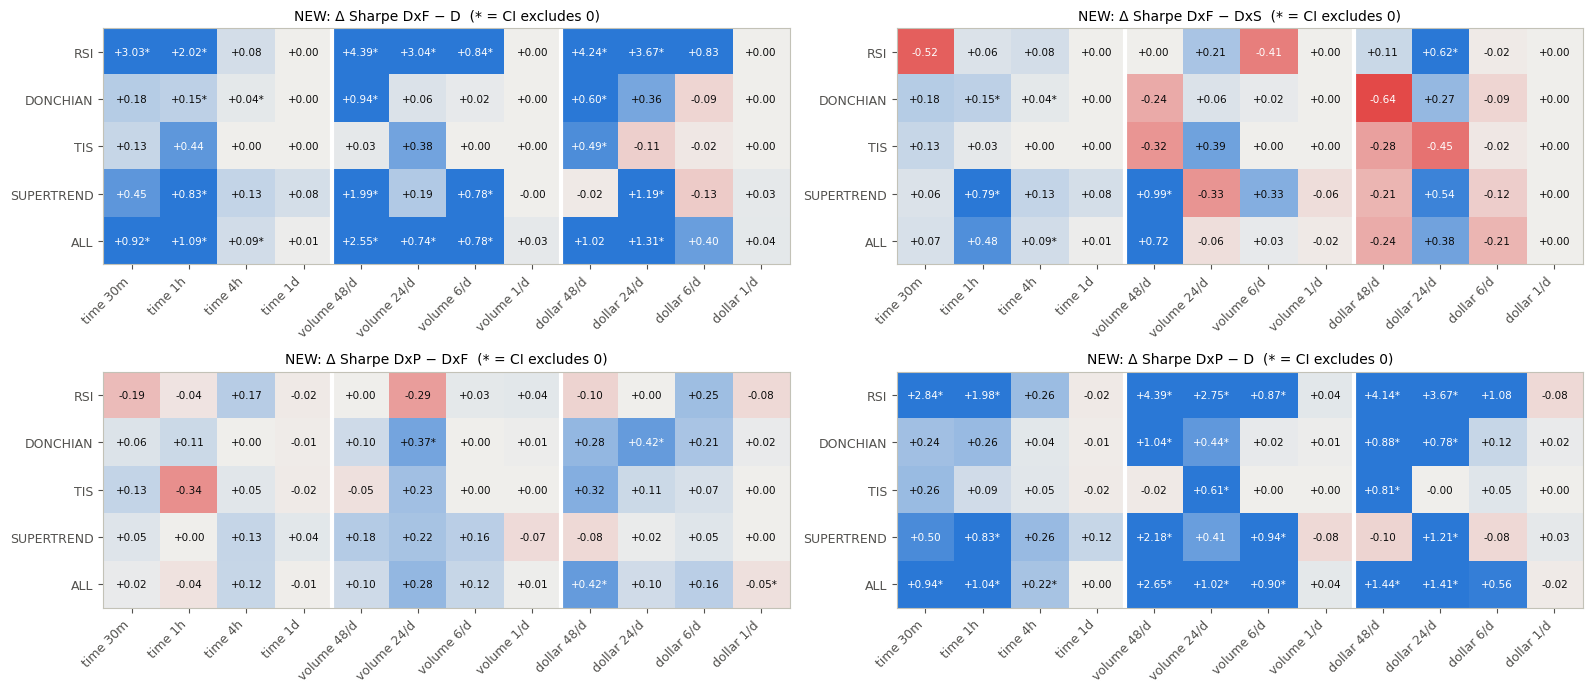

In [14]:
PAIRS_META = [("D", "U"), ("DxF", "D"), ("DxP", "DxF"), ("DxP", "D"), ("DxS", "D"), ("DxF", "DxS")]


def meta_table(g, fee=FEE_BPS):
    rows = []
    for p in PORTFOLIOS:
        for k in KEYS:
            ev = SIZES[k][0]
            m = ev["group"].eq(g) & (ev["strategy"].eq(p) if p != "ALL" else True) & ev["model"]
            row = {"portfolio": p, "config": CFG[k].label}
            for r in EVAL_RULES:
                row[f"Sharpe {r}"] = sharpe(PNL[(fee, g, k, p, r)])
            for a, b in PAIRS_META:
                row[f"{a} − {b}"] = fmt(delta(g, (k, p, a), (k, p, b), fee))
            row["filter accepts"] = float((ev.loc[m, "p"] >= ev.loc[m, "p_be"]).mean()) if m.any() else np.nan
            row["switch on"] = float((SIZES[k][1].loc[m, "DxS"] > 0).mean()) if m.any() else np.nan
            row["model coverage"] = STATS.loc[(g, p, k, "U"), "model coverage"]
            rows.append(row)
    return pd.DataFrame(rows).set_index(["portfolio", "config"])


META = {g: meta_table(g) for g in GROUPS}
print("NEW assets (transfer): value of inverse volatility, filtering and sizing [95 % paired CI]")
display(META["NEW"].round(3))

fig, axes = plt.subplots(2, 2, figsize=(16, 7))
for ax, (a, b) in zip(axes.ravel(), [("DxF", "D"), ("DxF", "DxS"), ("DxP", "DxF"), ("DxP", "D")]):
    est = pd.DataFrame({CFG[k].label: {p: delta("NEW", (k, p, a), (k, p, b))[0] for p in PORTFOLIOS} for k in KEYS})
    sig = pd.DataFrame({CFG[k].label: {p: (lambda t: t[1] > 0 or t[2] < 0)(delta("NEW", (k, p, a), (k, p, b))) for p in PORTFOLIOS} for k in KEYS})
    heat(ax, est, f"NEW: Δ Sharpe {a} − {b}  (* = CI excludes 0)", vmax=0.6, stars=sig)
fig.tight_layout(); plt.show()

### 7.3 The four rules side by side (all four strategies together)

`ALL` = the four strategy portfolios run together, capital 4 K = 80 notionals. Net PnL in thousands of USDT over the 93 months.

NEW: ALL portfolio by configuration and rule (net PnL in kUSD)


Sharpe                        net PnL                               max DD / K                      turnover (x K / yr)                              trades                            Sharpe 10 bps                     
rule             U      D    DxF    DxP         U         D       DxF       DxP          U      D    DxF    DxP                   U        D      DxF      DxP        U        D      DxF      DxP             U      D    DxF    DxP
time 30m    -1.837 -1.692 -0.772 -0.751 -1514.699 -1153.317  -519.955  -465.742     -1.900 -1.449 -0.691 -0.660             236.794  212.706  119.714  102.057  73179.0  72499.0  26075.0  25953.0        -2.734 -2.668 -1.320 -1.258
time 1h     -0.585 -0.507  0.579  0.536  -486.110  -356.757   457.589   362.798     -0.653 -0.517 -0.323 -0.180             123.249  111.785   74.001   57.934  38089.0  37719.0  14913.0  15020.0        -1.046 -1.000  0.290  0.271
time 4h      0.871  0.974  1.067  1.190   993.745   921.454  1008.542  1100.333     -0.195 -0.204 -0.193 -0.163              32.821   29.193   28.150   24.570  10143.0  10000.0   9242.0   9261.0         0.782  0.878  0.975  1.108
time 1d      0.935  0.788  0.800  0.791  2735.208  2593.221  2627.600  2582.117     -0.763 -0.853 -0.853 -0.853               7.484    6.764    6.744    6.614   2313.0   2260.0   2222.0   2217.0         0.926  0.781  0.793  0.785
volume 48/d -2.686 -2.745 -0.196 -0.098 -1504.150 -1183.897  -109.529   -54.525     -1.885 -1.484 -0.331 -0.345             223.391  200.532   82.214   71.417  69037.0  68867.0  10412.0  10378.0        -3.966 -4.245 -0.652 -0.493
volume 24/d -1.200 -1.074 -0.338 -0.057  -667.971  -474.894  -213.829   -35.824     -0.932 -0.709 -0.615 -0.576             113.454  101.647   51.578   46.670  35062.0  34961.0   9569.0   9608.0        -1.844 -1.802 -0.591 -0.289
volume 6/d  -0.105 -0.111  0.665  0.787   -63.556   -56.685   384.304   426.326     -0.351 -0.335 -0.137 -0.096              29.342   26.172   19.700   17.746   9068.0   9031.0   3932.0   3945.0        -0.255 -0.269  0.560  0.686
volume 1/d   0.712  0.445  0.475  0.481   383.080   171.008   175.122   178.317     -0.167 -0.153 -0.153 -0.153               4.747    4.039    3.877    3.755   1467.0   1467.0   1407.0   1407.0         0.685  0.412  0.442  0.449
dollar 48/d -2.095 -2.166 -1.146 -0.724 -1606.097 -1208.160  -360.055  -226.893     -2.068 -1.540 -0.469 -0.360             234.373  208.893   77.048   67.715  72431.0  72243.0  10464.0  10432.0        -3.010 -3.285 -1.913 -1.399
dollar 24/d -1.255 -1.238  0.076  0.171  -972.316  -715.410    25.966    56.414     -1.343 -0.964 -0.222 -0.155             115.658  103.166   35.465   30.776  35743.0  35633.0   6680.0   6653.0        -1.707 -1.778 -0.246 -0.118
dollar 6/d  -0.552 -0.549 -0.145  0.015  -365.260  -281.457   -25.903     2.476     -0.857 -0.629 -0.100 -0.081              27.029   23.605    6.795    5.700   8353.0   8335.0   2144.0   2147.0        -0.677 -0.691 -0.264 -0.091
dollar 1/d   0.024 -0.267 -0.231 -0.283    10.927   -89.010   -75.224   -91.618     -0.167 -0.173 -0.173 -0.183               4.896    4.106    3.997    4.119   1513.0   1513.0   1482.0   1481.0        -0.010 -0.306 -0.270 -0.323

SEEN: ALL portfolio by configuration and rule (net PnL in kUSD)


Sharpe                        net PnL                               max DD / K                      turnover (x K / yr)                              trades                            Sharpe 10 bps                     
rule             U      D    DxF    DxP         U         D       DxF       DxP          U      D    DxF    DxP                   U        D      DxF      DxP        U        D      DxF      DxP             U      D    DxF    DxP
time 30m    -0.767 -0.671  0.363  0.441  -585.760  -498.045   266.033   308.227     -0.775 -0.737 -0.380 -0.377             257.907  287.304  155.671  140.055  79704.0  77280.0  27480.0  27656.0        -1.822 -1.882 -0.294 -0.179
time 1h      0.126  0.210  1.086  1.276    97.266   158.779   832.372   952.093     -0.251 -0.256 -0.138 -0.104             134.419  150.539  116.970   98.223  41541.0  40329.0  17049.0  17265.0        -0.415 -0.408  0.615  0.870
time 4h      1.330  1.557  1.584  1.705  1345.548  1521.780  1569.713  1680.746     -0.141 -0.134 -0.138 -0.147              37.079   40.726   40.101   38.772  11459.0  11147.0  10466.0  10450.0         1.216  1.428  1.459  1.584
time 1d      1.083  1.101  1.103  1.114  2023.347  2239.230  2248.385  2274.075     -0.374 -0.337 -0.344 -0.301               8.766    9.565    9.601    9.576   2709.0   2614.0   2587.0   2577.0         1.068  1.086  1.088  1.099
volume 48/d -1.657 -1.195  0.400  0.650  -811.104  -583.816   217.828   328.340     -1.016 -0.766 -0.179 -0.092             230.600  269.352  101.646   86.276  71265.0  70494.0  10269.0  10278.0        -3.170 -2.989 -0.178  0.122
volume 24/d -0.239 -0.035  0.506  0.931  -123.400   -17.480   305.813   563.345     -0.300 -0.216 -0.197 -0.198             119.822  138.240   70.385   67.383  37030.0  36583.0  10025.0  10066.0        -0.966 -0.916  0.146  0.588
volume 6/d  -0.128  0.259  0.791  0.960   -68.099   138.508   476.664   573.252     -0.335 -0.174 -0.119 -0.102              32.326   36.281   23.907   22.120   9990.0   9854.0   4089.0   4114.0        -0.317  0.049  0.669  0.847
volume 1/d   1.101  0.976  0.897  0.919   523.367   401.517   360.690   374.287     -0.106 -0.090 -0.090 -0.094               5.142    5.817    5.655    5.577   1589.0   1581.0   1529.0   1534.0         1.067  0.932  0.853  0.876
dollar 48/d -1.843 -1.807 -0.505 -0.000 -1280.581 -1071.874  -164.981    -0.066     -1.650 -1.394 -0.276 -0.152             239.932  278.851   96.101   80.392  74149.0  73187.0   9899.0   9941.0        -2.869 -3.215 -1.425 -0.793
dollar 24/d -1.043 -0.957  0.816  0.999  -742.175  -571.877   300.124   350.221     -1.081 -0.845 -0.066 -0.049             120.036  138.775   52.219   49.406  37096.0  36610.0   7509.0   7403.0        -1.553 -1.667  0.379  0.567
dollar 6/d  -0.413 -0.183  0.781  0.962  -252.170  -100.056   183.745   224.721     -0.538 -0.354 -0.056 -0.054              29.666   33.940   11.418   11.288   9168.0   9067.0   2409.0   2398.0        -0.563 -0.375  0.632  0.814
dollar 1/d   0.577  0.430  0.507  0.493   227.904   157.161   182.475   175.821     -0.105 -0.088 -0.088 -0.086               5.122    5.795    5.714    5.870   1583.0   1575.0   1559.0   1558.0         0.536  0.381  0.457  0.441

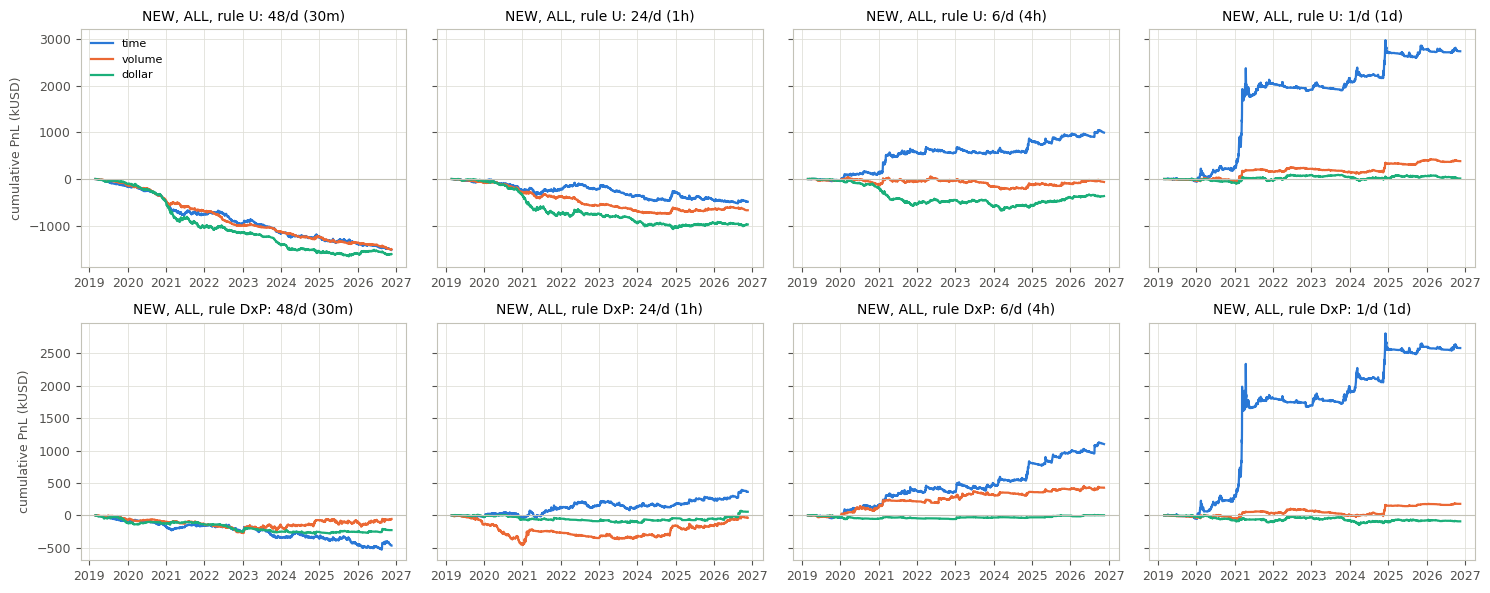

In [15]:
for g in GROUPS:
    t = STATS.xs((g, "ALL"), level=["group", "portfolio"])
    out = {}
    for col, scale in [("Sharpe", 1), ("net PnL", 1e3), ("max DD / K", 1), ("turnover (x K / yr)", 1), ("trades", 1), ("Sharpe 10 bps", 1)]:
        out[col] = (t[col] / scale).unstack("rule").reindex(index=KEYS, columns=list(RULES)).set_axis(LABELS, axis=0)
    tab = pd.concat(out, axis=1)
    print(f"{g}: ALL portfolio by configuration and rule (net PnL in kUSD)")
    display(tab.round(3))

fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharey="row")
for i, r in enumerate(["U", "DxP"]):
    for j, n in enumerate(FREQS):
        ax = axes[i, j]
        for bt in BAR_TYPES:
            k = qd.BarConfig(bt, n).key
            ax.plot(CAL, np.cumsum(PNL[(FEE_BPS, "NEW", k, "ALL", r)]) / 1e3, color=COL[bt], label=bt)
        ax.set_title(f"NEW, ALL, rule {r}: {FREQ_LABEL[n]}")
        ax.axhline(0, color="#c3c2b7", lw=0.8)
    axes[i, 0].set_ylabel("cumulative PnL (kUSD)")
axes[0, 0].legend(fontsize=8, loc="upper left")
fig.tight_layout(); plt.show()

### 7.3b Concentration: how much of the result comes from a few days?

Daily mark-to-market makes it possible to check whether a configuration's result rests on a handful of days. For the `ALL` book
under U and D×P: the Sharpe without the 10 best days of the 2 820, and the share of the net PnL earned on those 10 days.

In [16]:
rows = []
for g in GROUPS:
    for k in KEYS:
        for r in ("U", "DxP"):
            x = PNL[(FEE_BPS, g, k, "ALL", r)]
            top = np.argsort(x)[-10:]
            rows.append({"group": g, "config": CFG[k].label, "rule": r, "Sharpe": sharpe(x),
                         "Sharpe without 10 best days": sharpe(np.delete(x, top)), "net PnL (kUSD)": x.sum() / 1e3,
                         "share of PnL from 10 best days": x[top].sum() / x.sum() if x.sum() > 0 else np.nan})
CONC = pd.DataFrame(rows).set_index(["group", "config", "rule"])
for g in GROUPS:
    print(f"{g}: ALL book, concentration of the result in its 10 best days")
    display(CONC.loc[g].unstack("rule").reindex([CFG[k].label for k in KEYS]).round(3))

NEW: ALL book, concentration of the result in its 10 best days


Sharpe        Sharpe without 10 best days        net PnL (kUSD)           share of PnL from 10 best days        
rule           DxP      U                         DxP      U            DxP         U                            DxP       U
config                                                                                                                      
time 30m    -0.751 -1.837                      -1.303 -2.375       -465.742 -1514.699                            NaN     NaN
time 1h      0.536 -0.585                       0.001 -1.092        362.798  -486.110                          0.999     NaN
time 4h      1.190  0.871                       0.772  0.424       1100.333   993.745                          0.429   0.563
time 1d      0.791  0.935                       0.185  0.411       2582.117  2735.208                          0.842   0.657
volume 48/d -0.098 -2.686                      -0.623 -3.404        -54.525 -1504.150                            NaN     NaN
volume 24/d -0.057 -1.200                      -0.651 -1.727        -35.824  -667.971                            NaN     NaN
volume 6/d   0.787 -0.105                       0.361 -0.657        426.326   -63.556                          0.582     NaN
volume 1/d   0.481  0.712                      -0.084  0.178        178.317   383.080                          1.152   0.784
dollar 48/d -0.724 -2.095                      -1.465 -2.651       -226.893 -1606.097                            NaN     NaN
dollar 24/d  0.171 -1.255                      -0.577 -1.827         56.414  -972.316                          3.728     NaN
dollar 6/d   0.015 -0.552                      -0.698 -0.999          2.476  -365.260                         40.262     NaN
dollar 1/d  -0.283  0.024                      -0.694 -0.414        -91.618    10.927                            NaN  17.214

SEEN: ALL book, concentration of the result in its 10 best days


Sharpe        Sharpe without 10 best days        net PnL (kUSD)           share of PnL from 10 best days       
rule           DxP      U                         DxP      U            DxP         U                            DxP      U
config                                                                                                                     
time 30m     0.441 -0.767                      -0.081 -1.302        308.227  -585.760                          1.161    NaN
time 1h      1.276  0.126                       0.871 -0.334        952.093    97.266                          0.391  3.433
time 4h      1.705  1.330                       1.340  0.943       1680.746  1345.548                          0.301  0.358
time 1d      1.114  1.083                       0.675  0.670       2274.075  2023.347                          0.508  0.446
volume 48/d  0.650 -1.657                       0.225 -2.200        328.340  -811.104                          0.684    NaN
volume 24/d  0.931 -0.239                       0.510 -0.719        563.345  -123.400                          0.504    NaN
volume 6/d   0.960 -0.128                       0.479 -0.634        573.252   -68.099                          0.568    NaN
volume 1/d   0.919  1.101                       0.497  0.639        374.287   523.367                          0.509  0.505
dollar 48/d -0.000 -1.843                      -0.589 -2.361         -0.066 -1280.581                            NaN    NaN
dollar 24/d  0.999 -1.043                       0.521 -1.584        350.221  -742.175                          0.542    NaN
dollar 6/d   0.962 -0.413                       0.471 -0.904        224.721  -252.170                          0.587    NaN
dollar 1/d   0.493  0.577                       0.080  0.126        175.821   227.904                          0.850  0.803

### 7.4 After higher costs

The same trades, sizes and probabilities with 10 bps instead of 5 bps per fill (the meta-models are not refitted: a cost stress,
not a new design). High-frequency configurations trade more and lose more to costs.

In [17]:
for g in GROUPS:
    rows = {}
    for p in PORTFOLIOS:
        for k in KEYS:
            rows[(p, CFG[k].label)] = {"Sharpe U 5 bps": sharpe(PNL[(FEE_BPS, g, k, p, "U")]),
                                       "Sharpe U 10 bps": sharpe(PNL[(FEE_STRESS_BPS, g, k, p, "U")]),
                                       "Sharpe D×P 10 bps": sharpe(PNL[(FEE_STRESS_BPS, g, k, p, "DxP")]),
                                       "D×F − D, 10 bps": fmt(delta(g, (k, p, "DxF"), (k, p, "D"), FEE_STRESS_BPS)),
                                       "D×P − D×F, 10 bps": fmt(delta(g, (k, p, "DxP"), (k, p, "DxF"), FEE_STRESS_BPS)),
                                       "U − U(time 4h), 10 bps": fmt(delta(g, (k, p, "U"), (BASELINE, p, "U"), FEE_STRESS_BPS)) if k != BASELINE else ""}
    print(f"{g}: cost stress, 10 bps per fill")
    display(pd.DataFrame(rows).T.round(3))

NEW: cost stress, 10 bps per fill


Sharpe U 5 bps Sharpe U 10 bps Sharpe D×P 10 bps        D×F − D, 10 bps      D×P − D×F, 10 bps U − U(time 4h), 10 bps
RSI        time 30m         -3.921446       -5.686333          -0.87535  +4.76 [+3.13, +6.58]*   -0.19 [-0.74, +0.21]  -5.31 [-6.60, -4.12]*
           time 1h          -2.184719       -3.132088         -0.163569  +2.83 [+1.39, +3.94]*   -0.06 [-0.42, +0.64]  -2.76 [-3.89, -1.79]*
           time 4h            -0.1658       -0.372469         -0.247527   +0.09 [-0.06, +0.22]   +0.20 [-0.10, +0.47]                       
           time 1d           0.902963        0.881558          0.809888   +0.00 [+0.00, +0.00]   -0.02 [-0.06, +0.02]  +1.25 [+0.73, +1.89]*
           volume 48/d       -4.61361       -7.628683               0.0  +7.63 [+6.59, +8.84]*   +0.00 [+0.00, +0.00]  -7.26 [-8.32, -6.16]*
           volume 24/d      -2.803806       -4.534122         -0.199501  +4.78 [+3.00, +6.00]*   -0.31 [-0.56, +0.18]  -4.16 [-5.15, -3.15]*
           volume 6/d       -1.053989       -1.492543         -0.335699  +1.06 [+0.35, +1.75]*   +0.11 [-0.41, +0.68]  -1.12 [-1.74, -0.44]*
           volume 1/d        0.595529        0.545846          0.348838   +0.00 [-0.00, +0.00]  +0.04 [+0.00, +0.09]*  +0.92 [+0.29, +1.54]*
           dollar 48/d      -4.303615       -7.508194         -0.107628  +7.48 [+5.84, +8.78]*   -0.10 [-0.22, +0.00]  -7.14 [-8.38, -5.87]*
           dollar 24/d      -3.319966       -5.209095          0.618748  +5.62 [+4.63, +6.71]*   +0.00 [+0.00, +0.00]  -4.84 [-5.89, -3.78]*
           dollar 6/d       -0.886321       -1.438807          0.182662  +1.36 [+0.23, +2.55]*   +0.25 [-0.23, +0.58]  -1.07 [-1.99, -0.22]*
           dollar 1/d        0.411101        0.324395         -0.178438   +0.00 [+0.00, +0.00]   -0.08 [-0.17, +0.03]   +0.70 [-0.06, +1.39]
DONCHIAN   time 30m         -0.674977       -1.213118         -0.760686   +0.19 [-0.10, +0.45]   +0.12 [-0.21, +0.41]  -2.11 [-2.95, -1.28]*
           time 1h           0.642244        0.392835           0.66702  +0.16 [+0.01, +0.32]*   +0.14 [-0.17, +0.44]   -0.50 [-1.21, +0.11]
           time 4h           0.945875        0.894636          0.889951  +0.04 [+0.00, +0.10]*   +0.01 [-0.11, +0.13]                       
           time 1d           1.182238        1.175285          1.199483   +0.00 [+0.00, +0.00]   -0.01 [-0.05, +0.03]   +0.28 [-0.37, +0.90]
           volume 48/d       -1.29067       -2.103386         -0.729155  +1.21 [+0.54, +1.85]*   +0.20 [-0.21, +0.61]  -3.00 [-3.79, -2.26]*
           volume 24/d      -0.220106       -0.643787         -0.193909   +0.08 [-0.28, +0.42]  +0.41 [+0.07, +0.78]*  -1.54 [-2.24, -0.88]*
           volume 6/d         0.87995        0.786732          0.659137   +0.03 [-0.01, +0.07]   +0.00 [-0.18, +0.21]   -0.11 [-0.58, +0.32]
           volume 1/d        1.203334         1.19246          1.158808   +0.00 [+0.00, +0.00]   +0.01 [-0.02, +0.05]   +0.30 [-0.52, +1.06]
           dollar 48/d      -1.453918       -2.377417         -1.056538  +0.81 [+0.28, +1.38]*  +0.36 [+0.01, +0.72]*  -3.27 [-4.07, -2.49]*
           dollar 24/d      -0.488261         -1.0188           0.07319  +0.43 [+0.01, +0.87]*  +0.51 [+0.08, +0.98]*  -1.91 [-2.59, -1.23]*
           dollar 6/d        0.714835        0.594761          0.714638   -0.10 [-0.29, +0.09]   +0.22 [-0.05, +0.49]   -0.30 [-0.79, +0.18]
           dollar 1/d        1.080799        1.066057          1.094833   +0.00 [+0.00, +0.00]   +0.02 [-0.05, +0.11]   +0.17 [-0.49, +0.86]
TIS        time 30m         -0.854167       -1.194413         -0.762764   +0.19 [-0.23, +0.59]   +0.20 [-0.21, +0.55]  -2.24 [-2.92, -1.55]*
           time 1h          -0.734157       -0.908949         -0.441395   +0.53 [-0.24, +1.22]   -0.33 [-0.77, +0.07]  -1.96 [-2.62, -1.26]*
           time 4h           1.079754        1.046574          1.096197   +0.00 [+0.00, +0.00]   +0.05 [-0.02, +0.11]                       
           time 1d           0.769191         0.76505          0.579411   +

SEEN: cost stress, 10 bps per fill


Sharpe U 5 bps Sharpe U 10 bps Sharpe D×P 10 bps        D×F − D, 10 bps      D×P − D×F, 10 bps  U − U(time 4h), 10 bps
RSI        time 30m         -2.074936       -4.042918         -0.000682  +4.05 [+2.99, +5.21]*   +0.01 [-0.20, +0.13]   -4.84 [-6.06, -3.69]*
           time 1h          -0.287261        -1.29381          0.342189  +1.58 [+0.64, +2.60]*   +0.17 [-0.10, +0.45]   -2.09 [-2.71, -1.47]*
           time 4h           1.012204        0.792871          0.721609  +0.15 [+0.04, +0.28]*   -0.10 [-0.39, +0.15]                        
           time 1d           1.206125        1.174361          1.246606   +0.00 [+0.00, +0.00]   -0.01 [-0.04, +0.02]    +0.38 [-0.26, +0.99]
           volume 48/d      -3.983747       -7.595812               0.0  +7.48 [+6.41, +8.67]*   +0.00 [+0.00, +0.00]   -8.39 [-9.49, -7.23]*
           volume 24/d      -1.560353       -3.620291         -0.217733  +3.13 [+1.83, +4.33]*   -0.21 [-0.36, +0.04]   -4.41 [-5.43, -3.43]*
           volume 6/d         0.35422       -0.137433         -0.143434   -0.23 [-1.01, +0.48]   +0.04 [-0.22, +0.32]   -0.93 [-1.69, -0.17]*
           volume 1/d        0.969596        0.915826          0.826061   +0.00 [-0.00, +0.00]   +0.02 [-0.03, +0.08]    +0.12 [-0.44, +0.69]
           dollar 48/d      -4.458558        -8.48207         -0.359767  +7.61 [+6.33, +8.92]*   +0.00 [+0.00, +0.00]  -9.27 [-10.54, -7.88]*
           dollar 24/d      -2.092531        -4.41784         -0.469589  +3.33 [+2.23, +4.67]*   -0.01 [-0.04, +0.00]   -5.21 [-6.50, -3.95]*
           dollar 6/d       -0.154351       -0.768546          0.030873   +0.53 [-0.48, +1.55]   -0.03 [-0.24, +0.18]   -1.56 [-2.38, -0.78]*
           dollar 1/d        1.239106        1.159161          0.999377   +0.00 [+0.00, +0.00]   -0.01 [-0.07, +0.05]    +0.37 [-0.21, +0.92]
DONCHIAN   time 30m            0.6028        0.035414          0.241869   +0.16 [-0.01, +0.34]   +0.07 [-0.18, +0.30]   -1.75 [-2.25, -1.25]*
           time 1h           1.491305        1.202449          1.495384  +0.10 [+0.02, +0.18]*  +0.31 [+0.05, +0.56]*   -0.59 [-1.16, -0.08]*
           time 4h           1.854524        1.789726          1.890224   -0.01 [-0.03, +0.01]   +0.07 [-0.03, +0.19]                        
           time 1d           1.086577        1.076907          1.135001   +0.00 [+0.00, +0.00]   -0.01 [-0.04, +0.02]   -0.71 [-1.23, -0.24]*
           volume 48/d      -0.116756       -1.017972          0.012748  +0.96 [+0.35, +1.59]*   -0.07 [-0.41, +0.27]   -2.81 [-3.44, -2.15]*
           volume 24/d        0.60444        0.149369          0.841034   +0.19 [-0.02, +0.42]  +0.46 [+0.13, +0.79]*   -1.64 [-2.25, -1.04]*
           volume 6/d        1.220098        1.109481          1.397893   +0.02 [-0.04, +0.08]  +0.37 [+0.17, +0.58]*   -0.68 [-1.20, -0.22]*
           volume 1/d        1.538432        1.524847          1.466459   +0.00 [+0.00, +0.00]   -0.04 [-0.10, +0.00]    -0.26 [-0.81, +0.24]
           dollar 48/d      -0.311571       -1.326264         -0.411316   +0.38 [-0.28, +1.07]   +0.40 [-0.06, +0.85]   -3.12 [-3.79, -2.40]*
           dollar 24/d       0.454452       -0.095872          0.689371  +0.44 [+0.09, +0.80]*   +0.21 [-0.10, +0.53]   -1.89 [-2.47, -1.33]*
           dollar 6/d        1.149158        1.017794          1.270795   -0.01 [-0.13, +0.10]   +0.27 [-0.03, +0.54]   -0.77 [-1.25, -0.31]*
           dollar 1/d        1.458028        1.439406          1.436202   +0.00 [+0.00, +0.00]   -0.01 [-0.07, +0.04]    -0.35 [-0.89, +0.11]
TIS        time 30m         -0.130809       -0.553545            0.2757  +0.56 [+0.24, +0.84]*   +0.22 [-0.19, +0.62]   -1.59 [-2.22, -0.86]*
           time 1h          -0.354891        -0.56433         -0.011087   +0.29 [-0.41, +0.99]   -0.01 [-0.27, +0.30]   -1.60 [-2.24, -0.85]*
           time 4h           1.072413        1.032263          1.268652   +0.00 [+0.00, +0.00]   +0.04 [-0.00, +0.10]                        
           time 1d           0.951476        0.

### 7.5 Training assets (`SEEN`)

The same decomposition on the 20 assets the meta-models train on (in-sample with respect to the asset universe, out-of-sample in
time).

In [18]:
display(META["SEEN"].round(3))

Sharpe U  Sharpe D  Sharpe DxF  Sharpe DxP  Sharpe DxS                  D − U                DxF − D              DxP − DxF                DxP − D                DxS − D              DxF − DxS  filter accepts  \
portfolio  config                                                                                                                                                                                                                          
RSI        time 30m       -2.075    -1.875       0.243       0.235       0.000   +0.20 [-0.18, +0.57]  +2.12 [+1.25, +3.03]*   -0.01 [-0.19, +0.12]  +2.11 [+1.26, +2.98]*  +1.87 [+1.13, +2.78]*   +0.24 [-0.53, +0.74]           0.020   
           time 1h        -0.287    -0.273       0.673       0.729       0.000   +0.01 [-0.32, +0.32]  +0.95 [+0.13, +1.84]*   +0.06 [-0.19, +0.31]  +1.00 [+0.17, +1.93]*   +0.27 [-0.39, +1.05]   +0.67 [-0.02, +1.29]           0.137   
           time 4h         1.012     0.925       1.061       0.980       0.925   -0.09 [-0.33, +0.17]  +0.14 [+0.03, +0.26]*   -0.08 [-0.34, +0.15]   +0.06 [-0.21, +0.30]   +0.00 [+0.00, +0.00]  +0.14 [+0.03, +0.26]*           0.921   
           time 1d         1.206     1.289       1.289       1.280       1.289   +0.08 [-0.09, +0.27]   +0.00 [+0.00, +0.00]   -0.01 [-0.04, +0.02]   -0.01 [-0.04, +0.02]   +0.00 [+0.00, +0.00]   +0.00 [+0.00, +0.00]           1.000   
           volume 48/d    -3.984    -3.409       0.000       0.000       0.000  +0.58 [+0.08, +1.02]*  +3.41 [+2.47, +4.47]*   +0.00 [+0.00, +0.00]  +3.41 [+2.47, +4.47]*  +3.41 [+2.47, +4.47]*   +0.00 [+0.00, +0.00]           0.000   
           volume 24/d    -1.560    -0.927       0.277       0.152       0.000  +0.63 [+0.23, +1.02]*  +1.20 [+0.11, +2.17]*   -0.13 [-0.29, +0.05]   +1.08 [-0.04, +2.13]  +0.93 [+0.17, +1.82]*   +0.28 [-0.59, +0.72]           0.014   
           volume 6/d      0.354     0.547       0.109       0.099       0.514   +0.19 [-0.21, +0.57]   -0.44 [-1.16, +0.24]   -0.01 [-0.28, +0.26]   -0.45 [-1.21, +0.23]   -0.03 [-0.76, +0.56]   -0.41 [-0.85, +0.03]           0.268   
           volume 1/d      0.970     0.883       0.883       0.903       0.883   -0.09 [-0.29, +0.18]   +0.00 [-0.00, +0.00]   +0.02 [-0.03, +0.08]   +0.02 [-0.03, +0.08]   +0.00 [+0.00, +0.00]   +0.00 [-0.00, +0.00]           1.000   
           dollar 48/d    -4.459    -3.599       0.360       0.360       0.000  +0.86 [+0.28, +1.39]*  +3.96 [+2.96, +5.25]*   +0.00 [+0.00, +0.00]  +3.96 [+2.96, +5.25]*  +3.60 [+2.56, +4.83]*  +0.36 [+0.36, +0.72]*           0.000   
           dollar 24/d    -2.093    -1.338      -0.233      -0.258       0.000  +0.75 [+0.33, +1.17]*  +1.10 [+0.07, +2.24]*   -0.02 [-0.12, +0.00]  +1.08 [+0.05, +2.19]*  +1.34 [+0.56, +2.25]*   -0.23 [-0.94, +0.39]           0.001   
           dollar 6/d     -0.154     0.148       0.214       0.194       0.000   +0.30 [-0.09, +0.63]   +0.07 [-0.90, +1.01]   -0.02 [-0.23, +0.17]   +0.05 [-0.90, +0.96]   -0.15 [-0.88, +0.76]   +0.21 [-0.53, +0.76]           0.013   
           dollar 1/d      1.239     1.102       1.102       1.095       1.102   -0.14 [-0.36, +0.15]   +0.00 [+0.00, +0.00]   -0.01 [-0.06, +0.05]   -0.01 [-0.06, +0.05]   +0.00 [+0.00, +0.00]   +0.00 [+0.00, +0.00]           1.000   
DONCHIAN   time 30m        0.603     0.672       0.818       0.864       0.672   +0.07 [-0.21, +0.33]   +0.15 [-0.02, +0.31]   +0.05 [-0.18, +0.26]   +0.19 [-0.10, +0.46]   +0.00 [+0.00, +0.00]   +0.15 [-0.02, +0.31]           0.911   
           time 1h         1.491     1.415       1.511       1.800       1.415   -0.08 [-0.34, +0.18]  +0.10 [+0.02, +0.17]*  +0.29 [+0.04, +0.53]*  +0.39 [+0.09, +0.67]*   +0.00 [+0.00, +0.00]  +0.10 [+0.02, +0.17]*           0.960   
           time 4h         1.855     1.903       1.893       1.968       1.903   +0.05 [-0.14, +0.23]   -0.01 [-0.03, +0.01]   +0.07 [-0.03, +0.19]   +0.06 [-0.04, +0.18]   +0.00 [+0.00, +0.00]   -0.01 [-0.03, +0.01]           0.993   
           t

## 8. Where the comparison is weak: flags

A configuration × strategy cell is flagged when its conclusion rests on thin ground:

* **sparse trades** — fewer than 200 trades of the strategy on `NEW` assets in 93 months;
* **low model coverage** — less than 75 % of the evaluated trades had a fitted meta-model (the rest fall back to `D`, so the
  filter and sizing effects are diluted);
* **realised frequency off target** — the median asset's achieved bars per day is outside 0.8–1.25 × the target, so the
  configuration does not sample at the frequency it is compared at;
* **TIS daily candles incomplete** — fewer than 90 % of days pass TIS's own coverage rule for its daily confirmation;
* **volume filter uninformative** — SuperTrend's volume filter on volume bars (every bar carries the threshold volume).

In [19]:
rows = []
for k in KEYS:
    for s in SS:
        st = STATS.loc[("NEW", s, k, "U")]
        cov = COVERAGE.loc[(s, CFG[k].label), "model coverage (all)"]
        ratio = SAMPLING.loc[CFG[k].label, "ratio median"]
        htf = INFO[k]["tis_htf_complete"].median()
        flags = []
        if st["signals"] < MIN_TRADES_NEW:
            flags.append("sparse trades")
        if not cov >= MIN_MODEL_COVERAGE:
            flags.append("low model coverage")
        if not FREQ_RATIO_BAND[0] <= ratio <= FREQ_RATIO_BAND[1]:
            flags.append("realised frequency off target")
        if s == "TIS" and htf < MIN_HTF_COMPLETE:
            flags.append("TIS daily candles incomplete")
        if s == "SUPERTREND" and CFG[k].bar_type == "volume":
            flags.append("volume filter uninformative")
        rows.append({"config": CFG[k].label, "strategy": s, "NEW trades": int(st["signals"]),
                     "months with trades (NEW)": int(st["months with trades"]), "model coverage": cov,
                     "achieved / target": ratio, "TIS daily candle complete": htf if s == "TIS" else np.nan,
                     "flags": "; ".join(flags)})
FLAGS = pd.DataFrame(rows).set_index(["strategy", "config"]).sort_index(level=0, sort_remaining=False)
display(FLAGS.round(3))
print(f"flagged cells: {int((FLAGS['flags'] != '').sum())} of {len(FLAGS)}")

NEW trades  months with trades (NEW)  model coverage  achieved / target  TIS daily candle complete                                              flags
strategy   config                                                                                                                                                            
DONCHIAN   time 30m          12753                        93           1.000              0.999                        NaN                                                   
           time 1h            6193                        93           1.000              0.999                        NaN                                                   
           time 4h            1569                        92           0.929              1.000                        NaN                                                   
           time 1d             260                        57           0.308              1.000                        NaN                                 low model coverage
           volume 48/d       14815                        93           1.000              1.040                        NaN                                                   
           volume 24/d        7256                        93           1.000              1.047                        NaN                                                   
           volume 6/d         1706                        92           0.910              1.053                        NaN                                                   
           volume 1/d          280                        60           0.357              1.058                        NaN                                 low model coverage
           dollar 48/d       15255                        93           1.000              1.068                        NaN                                                   
           dollar 24/d        7427                        93           1.000              1.075                        NaN                                                   
           dollar 6/d         1791                        93           0.907              1.084                        NaN                                                   
           dollar 1/d          294                        62           0.364              1.086                        NaN                                 low model coverage
RSI        time 30m          29817                        93           1.000              0.999                        NaN                                                   
           time 1h           15675                        93           1.000              0.999                        NaN                                                   
           time 4h            4286                        93           1.000              1.000                        NaN                                                   
           time 1d             816                        75           0.716              1.000                        NaN                                 low model coverage
           volume 48/d       32061                        93           1.000              1.040                        NaN                                                   
           volume 24/d       16328                        93           1.000              1.047                        NaN                                                   
           volume 6/d         4266                        92           1.000              1.053                        NaN                                                   
           volume 1/d          876                        72           0.713              1.058                        NaN                                 low model coverage
           dollar 48/d       33077                        93           1.000              1.068                        NaN                                                   
           dollar 24/d

flagged cells: 19 of 48


## 9. Summary of the comparisons (computed)

For every portfolio on `NEW`: the baseline (time 4h) Sharpe of U and of D×P, the configurations whose U or D×P Sharpe is
distinguishable from the baseline's, and the configurations where filtering, sizing or inverse volatility add value with an
interval that excludes zero. "flagged" marks cells listed in §8.

In [20]:
def flagged(p, k):
    return p != "ALL" and FLAGS.loc[(p, CFG[k].label), "flags"] != ""


rows = []
for g in GROUPS:
    for p in PORTFOLIOS:
        row = {"group": g, "portfolio": p, "baseline U": sharpe(PNL[(FEE_BPS, g, BASELINE, p, "U")]),
               "baseline D×P": sharpe(PNL[(FEE_BPS, g, BASELINE, p, "DxP")])}
        for rule in ("U", "DxP"):
            better, worse = [], []
            for k in KEYS:
                if k == BASELINE:
                    continue
                est, lo, hi, _ = delta(g, (k, p, rule), (BASELINE, p, rule))
                tag = CFG[k].label + (" (flagged)" if flagged(p, k) else "")
                if lo > 0:
                    better.append(f"{tag} {est:+.2f}")
                elif hi < 0:
                    worse.append(f"{tag} {est:+.2f}")
            row[f"{rule} better than baseline"] = ", ".join(better) or "none"
            row[f"{rule} worse than baseline"] = ", ".join(worse) or "none"
        for a, b in PAIRS_META:
            hits = []
            for k in KEYS:
                est, lo, hi, _ = delta(g, (k, p, a), (k, p, b))
                if lo > 0:
                    hits.append(f"{CFG[k].label} {est:+.2f}")
                elif hi < 0:
                    hits.append(f"{CFG[k].label} {est:+.2f} (worse)")
            row[f"{a} − {b} ≠ 0"] = ", ".join(hits) or "none"
        rows.append(row)
SUMMARY = pd.DataFrame(rows).set_index(["group", "portfolio"])
with pd.option_context("display.max_colwidth", 400):
    display(SUMMARY.loc["NEW"])
    display(SUMMARY.loc["SEEN"])

best = STATS.xs(("NEW", "U"), level=["group", "rule"])["Sharpe"].unstack("config")[KEYS]
print("Best configuration by U Sharpe on NEW, per portfolio:", {p: CFG[best.loc[p].idxmax()].label for p in PORTFOLIOS})
best2 = STATS.xs(("NEW", "DxP"), level=["group", "rule"])["Sharpe"].unstack("config")[KEYS]
print("Best configuration by D×P Sharpe on NEW, per portfolio:", {p: CFG[best2.loc[p].idxmax()].label for p in PORTFOLIOS})
print(f"total runtime {(time.time() - T0) / 60:.1f} min")

,baseline U,baseline D×P,U better than baseline,U worse than baseline,DxP better than baseline,DxP worse than baseline,D − U ≠ 0,DxF − D ≠ 0,DxP − DxF ≠ 0,DxP − D ≠ 0,DxS − D ≠ 0,DxF − DxS ≠ 0
portfolio,,,,,,,,,,,,
RSI,-0.165800,-0.058619,"time 1d (flagged) +1.07, volume 1/d (flagged) +0.76","time 30m -3.76, time 1h -2.02, volume 48/d -4.45, volume 24/d -2.64, volume 6/d -0.89, dollar 48/d -4.14, dollar 24/d -3.15","time 1d (flagged) +0.90, dollar 24/d +0.68",none,"volume 1/d -0.22 (worse), dollar 1/d -0.41 (worse)","time 30m +3.03, time 1h +2.02, volume 48/d +4.39, volume 24/d +3.04, volume 6/d +0.84, dollar 48/d +4.24, dollar 24/d +3.67",none,"time 30m +2.84, time 1h +1.98, volume 48/d +4.39, volume 24/d +2.75, volume 6/d +0.87, dollar 48/d +4.14, dollar 24/d +3.67","time 30m +3.54, time 1h +1.95, volume 48/d +4.39, volume 24/d +2.82, volume 6/d +1.24, dollar 48/d +4.12, dollar 24/d +3.05, dollar 6/d +0.85",dollar 24/d +0.62
DONCHIAN,0.945875,0.941765,none,"time 30m -1.62, volume 48/d -2.24, volume 24/d -1.17, dollar 48/d -2.40, dollar 24/d -1.43",none,"time 30m -1.20, volume 48/d -1.08, volume 24/d -0.72, dollar 48/d -1.30",none,"time 1h +0.15, time 4h +0.04, volume 48/d +0.94, dollar 48/d +0.60","volume 24/d +0.37, dollar 24/d +0.42","volume 48/d +1.04, volume 24/d +0.44, dollar 48/d +0.88, dollar 24/d +0.78","volume 48/d +1.18, dollar 48/d +1.24","time 1h +0.15, time 4h +0.04"
TIS,1.079754,1.131774,none,"time 30m -1.93, time 1h -1.81, volume 48/d -1.81, volume 24/d (flagged) -1.70, volume 6/d (flagged) -1.10, volume 1/d (flagged) -1.44, dollar 48/d -1.97, dollar 24/d (flagged) -1.82, dollar 6/d (flagged) -1.26, dollar 1/d (flagged) -1.65",none,"time 30m -1.66, time 1h -1.49, volume 48/d -1.93, volume 24/d (flagged) -1.17, volume 6/d (flagged) -1.07, volume 1/d (flagged) -1.50, dollar 48/d -1.23, dollar 24/d (flagged) -1.85, dollar 6/d (flagged) -1.21, dollar 1/d (flagged) -1.71",time 1h +0.28,dollar 48/d +0.49,none,"volume 24/d +0.61, dollar 48/d +0.81",none,none
SUPERTREND,0.506835,1.081264,none,"time 30m -1.45, volume 48/d (flagged) -2.23, volume 24/d (flagged) -1.22, dollar 48/d -1.57, dollar 24/d -1.17",none,"time 30m -1.52, volume 48/d (flagged) -0.77, volume 24/d (flagged) -1.19, volume 1/d (flagged) -1.43, dollar 48/d -2.28, dollar 6/d -1.76, dollar 1/d (flagged) -1.76","time 4h +0.31, time 1d +0.23","time 1h +0.83, volume 48/d +1.99, volume 6/d +0.78, dollar 24/d +1.19",none,"time 1h +0.83, volume 48/d +2.18, volume 6/d +0.94, dollar 24/d +1.21",volume 48/d +1.01,"time 1h +0.79, volume 48/d +0.99"
ALL,0.870903,1.190292,none,"time 30m -2.71, time 1h -1.46, volume 48/d -3.56, volume 24/d -2.07, volume 6/d -0.98, dollar 48/d -2.97, dollar 24/d -2.13, dollar 6/d -1.42",none,"time 30m -1.94, time 1h -0.65, volume 48/d -1.29, volume 24/d -1.25, dollar 48/d -1.91, dollar 24/d -1.02, dollar 6/d -1.18, dollar 1/d -1.47","volume 1/d -0.27 (worse), dollar 1/d -0.29 (worse)","time 30m +0.92, time 1h +1.09, time 4h +0.09, volume 48/d +2.55, volume 24/d +0.74, volume 6/d +0.78, dollar 24/d +1.31","dollar 48/d +0.42, dollar 1/d -0.05 (worse)","time 30m +0.94, time 1h +1.04, time 4h +0.22, volume 48/d +2.65, volume 24/d +1.02, volume 6/d +0.90, dollar 48/d +1.44, dollar 24/d +1.41","time 30m +0.85, time 1h +0.61, volume 48/d +1.83, volume 24/d +0.80, volume 6/d +0.75, dollar 48/d +1.26",time 4h +0.09


,baseline U,baseline D×P,U better than baseline,U worse than baseline,DxP better than baseline,DxP worse than baseline,D − U ≠ 0,DxF − D ≠ 0,DxP − DxF ≠ 0,DxP − D ≠ 0,DxS − D ≠ 0,DxF − DxS ≠ 0
portfolio,,,,,,,,,,,,
RSI,1.012204,0.979898,none,"time 30m -3.09, time 1h -1.30, volume 48/d -5.00, volume 24/d -2.57, dollar 48/d -5.47, dollar 24/d -3.10, dollar 6/d -1.17",none,"volume 48/d -0.98, volume 24/d -0.83, volume 6/d -0.88, dollar 24/d -1.24","volume 48/d +0.58, volume 24/d +0.63, dollar 48/d +0.86, dollar 24/d +0.75","time 30m +2.12, time 1h +0.95, time 4h +0.14, volume 48/d +3.41, volume 24/d +1.20, dollar 48/d +3.96, dollar 24/d +1.10",none,"time 30m +2.11, time 1h +1.00, volume 48/d +3.41, dollar 48/d +3.96, dollar 24/d +1.08","time 30m +1.87, volume 48/d +3.41, volume 24/d +0.93, dollar 48/d +3.60, dollar 24/d +1.34","time 4h +0.14, dollar 48/d +0.36"
DONCHIAN,1.854524,1.967730,none,"time 30m -1.25, time 1d (flagged) -0.77, volume 48/d -1.97, volume 24/d -1.25, volume 6/d -0.63, dollar 48/d -2.17, dollar 24/d -1.40, dollar 6/d -0.71",none,"time 30m -1.10, time 1d (flagged) -0.82, volume 48/d -1.22, volume 24/d -0.66, dollar 48/d -1.51, dollar 24/d -0.76, dollar 6/d -0.55, dollar 1/d (flagged) -0.51","volume 48/d +0.32, dollar 48/d +0.29","time 1h +0.10, volume 48/d +0.70, dollar 24/d +0.38","time 1h +0.29, volume 24/d +0.41, volume 6/d +0.36","time 1h +0.39, volume 24/d +0.60, volume 6/d +0.38, dollar 24/d +0.58",none,"time 1h +0.10, volume 48/d +0.91, dollar 24/d +0.56"
TIS,1.072413,1.307591,none,"time 30m -1.20, time 1h -1.43, volume 48/d -1.72, volume 24/d (flagged) -1.41, volume 6/d (flagged) -1.50, volume 1/d (flagged) -1.70, dollar 48/d -2.09, dollar 24/d (flagged) -1.28",none,"time 30m -0.74, time 1h -1.18, volume 48/d -1.01, volume 24/d (flagged) -1.23, volume 6/d (flagged) -1.71, volume 1/d (flagged) -1.93, dollar 48/d -0.92, dollar 24/d (flagged) -0.89, dollar 6/d (flagged) -1.14, dollar 1/d (flagged) -1.17","time 1h +0.30, dollar 48/d +0.36","time 30m +0.43, dollar 48/d +0.67",dollar 48/d +0.38,"time 30m +0.58, volume 48/d +0.68, dollar 48/d +1.05",none,time 30m +0.43
SUPERTREND,0.489548,1.011300,none,"time 30m -1.22, time 1h -0.79, volume 48/d (flagged) -1.49, volume 6/d (flagged) -1.20, dollar 48/d -1.53, dollar 24/d -1.32, dollar 6/d -1.17, dollar 1/d (flagged) -1.07",none,"time 30m -1.17, volume 1/d (flagged) -1.22, dollar 48/d -2.17, dollar 6/d -1.11, dollar 1/d (flagged) -1.63","time 4h +0.33, volume 48/d +0.27, volume 6/d +0.44, dollar 1/d -0.11 (worse)","time 1h +0.80, volume 48/d +0.81, volume 6/d +0.84, dollar 24/d +1.20",none,"time 1h +0.91, volume 48/d +1.07, volume 6/d +0.89, dollar 24/d +1.20","time 30m +0.55, dollar 24/d +0.90","time 1h +0.68, volume 1/d -0.17 (worse), dollar 48/d -0.35 (worse)"
ALL,1.329758,1.705488,none,"time 30m -2.10, time 1h -1.20, volume 48/d -2.99, volume 24/d -1.57, volume 6/d -1.46, dollar 48/d -3.17, dollar 24/d -2.37, dollar 6/d -1.74, dollar 1/d -0.75",none,"time 30m -1.26, time 1d -0.59, volume 48/d -1.06, volume 24/d -0.77, volume 6/d -0.75, volume 1/d -0.79, dollar 48/d -1.71, dollar 24/d -0.71, dollar 6/d -0.74, dollar 1/d -1.21","volume 48/d +0.46, volume 6/d +0.39, dollar 6/d +0.23","time 30m +1.03, time 1h +0.88, volume 48/d +1.60, volume 6/d +0.53, dollar 48/d +1.30, dollar 24/d +1.77, dollar 6/d +0.96","volume 24/d +0.43, dollar 48/d +0.50","time 30m +1.11, time 1h +1.07, volume 48/d +1.85, volume 24/d +0.97, volume 6/d +0.70, dollar 48/d +1.81, dollar 24/d +1.96, dollar 6/d +1.14","time 30m +0.87, time 1h +0.35, volume 24/d +0.69, volume 6/d +0.77, dollar 48/d +1.05, dollar 24/d +1.39, dollar 6/d +0.92","time 1h +0.52, volume 48/d +1.11"


Best configuration by U Sharpe on NEW, per portfolio: {'RSI': 'time 1d', 'DONCHIAN': 'volume 1/d', 'TIS': 'time 4h', 'SUPERTREND': 'time 4h', 'ALL': 'time 1d'}
Best configuration by D×P Sharpe on NEW, per portfolio: {'RSI': 'time 1d', 'DONCHIAN': 'time 1d', 'TIS': 'time 4h', 'SUPERTREND': 'time 4h', 'ALL': 'time 4h'}
total runtime 1.3 min


## 10. Conclusions

All numbers are copied from the outputs above. `NEW` = the 20 assets no model ever trained on (main result); Sharpe = annualised
Sharpe of daily mark-to-market PnL, net of 5 bps per fill, fixed budget of 20 notionals per strategy, 2019-03-01 → 2026-11-19;
brackets are 95 % paired monthly block-bootstrap intervals; `ALL` = the four strategies together.

### 10.1 Data and sampling

* **Event bars from every trade.** 15.2 billion aggTrades (232 GB of archive) were turned into volume and dollar bars for all 40
  assets, with no missing archive file. Two archive defects were found and removed: 138 zero-price records (BTC, ETH, BNB, LTC in
  2017-12 / 2018-01) and 14.0 million repeated records (the ETHUSDT 2018-01 file holds parts of the month four times; BTC and XRP
  repeat some trades of 2026-02-11). After that, the daily traded volume of every asset-day equals the 1-day klines to 4e-6.
* **Realised frequency.** Time bars hit their targets exactly (30m bars lose 901 bars without trades, which become segment
  breaks). Event bars run **4–9 % above target** (median asset 1.04–1.09; worst asset 1.24, DOGE dollar bars): volume grew
  over the sample and a trailing 30-day threshold lags growth. Per asset-year, 80 % of the ratios lie within 0.92–1.25, and no
  configuration's median asset is outside the flag band. Durations of event bars are wide: at 6 bars per day (nominal 4 h) the
  median bar lasts ~3 h, about 5 % last under a quarter of an hour and 5 % over 9.5 h; the realised frequency follows activity
  over time (figure in §3).
* **The 4h baseline reproduces the reference exactly**: 22 389 closed trades, identical trade by trade over the whole reference
  history, through the new `load_bars` interface.

### 10.2 Where the primary strategy itself improves (rule U)

| `ALL`, NEW | 48/d (30m) | 24/d (1h) | 6/d (4h) | 1/d (1d) |
|---|---|---|---|---|
| time | −1.84 | −0.59 | **+0.87** | **+0.94** |
| volume | −2.69 | −1.20 | −0.11 | +0.71 |
| dollar | −2.10 | −1.26 | −0.55 | +0.02 |

* **Frequency dominates bar type, and higher frequency is decisively worse after costs.** Every 30m / 1h / 48-per-day /
  24-per-day configuration is significantly worse than time 4h for the four-strategy book (Δ −1.5 to −3.6). Per-trade gross
  edges shrink faster than costs (Donchian on time bars: +1 828 bps net per trade at 1d, +184 at 4h, +26 at 1h, −13 at 30m) while
  turnover rises from 7 × K per year (1d) to 33 (4h) and 237 (30m).
* **Event bars do not improve these strategies at any frequency.** Their Sharpe for the book is below that of time bars of the
  same frequency at every frequency; at 6 per day volume bars are −0.98 [−1.63, −0.27] and dollar bars −1.42 [−2.64, −0.11] below
  time 4h. Two of the four rules depend on time-bar semantics: **TIS** needs day-aligned candles for its daily confirmation (on
  event bars only 93 / 76 / 29 / 5 % of days pass at 48 / 24 / 6 / 1 bars per day, and it all but stops trading), and
  **SuperTrend**'s volume filter is uninformative on volume bars (it is negative on every event-bar configuration). Donchian is
  the only strategy for which event bars are competitive (volume 1/d +1.20, dollar 1/d +1.08 vs time 4h +0.95, not significant).
* **Daily time bars are the only statistically indistinguishable alternative to 4h** for the book: +0.94 vs +0.87,
  Δ +0.06 [−0.45, +0.59] on NEW, −0.25 [−0.80, +0.30] on SEEN, with larger net PnL per unit of capital (return on K 0.44 vs 0.16 per
  year) but a four times deeper drawdown (−0.76 K vs −0.20 K), and it rests on fewer days: without its 10 best days (of 2 820)
  the daily book's Sharpe falls from 0.94 to 0.41 (66 % of its net PnL was earned on those days, in two bursts in early 2021 and
  late 2024), the 4h book's from 0.87 to 0.42. By strategy, RSI turns from a loser at 4h (−0.17) into a winner on daily bars
  (+0.90, Δ +1.07 [+0.55, +1.69]); Donchian is +0.24 (n.s.) better daily; TIS and SuperTrend are best at time 4h.

### 10.3 Where meta-labeling adds value (filter D×F, sizing D×P)

* **At the 4h baseline meta-labeling adds a modest, significant amount**: D×P − D = **+0.22 [+0.06, +0.41]** (U 0.87 → D 0.97 →
  D×F 1.07 → D×P 1.19), of which the filter is +0.09 [+0.02, +0.17] and probability sizing +0.12 [−0.02, +0.29] (not
  significant). This is the same size as the reference notebook's +0.23 with a much simpler model, and at 4h the filter's value is
  trade selection (the strategy-level switch never turns a strategy off there).
* **The large "gains" at high frequency are mostly a strategy-level off switch, not trade selection.** For the book the filter
  adds +0.74 to +2.55 in six configurations (time 30m and 1h, volume 48 / 24 / 6 per day, dollar 24 per day; +1.02 on dollar 48/d
  with an interval touching zero), but the model-free diagnostic D×S — switch a strategy off when its training trades lost money —
  captures most of it: D×S − D is significant in five of the six (all but dollar 24/d), and D×F − D×S is not distinguishable from
  zero in any of them. The rescued books also stay below the 4h baseline: the best are volume 6/d D×P (+0.79) and time 1h D×F
  (+0.58); the others remain near or below zero.
* **Probability sizing beyond the filter** (D×P − D×F) is significant for the book only on dollar 48/d (+0.42) and for Donchian on
  24-per-day event bars; it is slightly harmful on dollar 1/d (−0.05).
* **On daily bars meta-labeling adds nothing** (the filter accepts 92–98 % of trades; models exist for only 54–64 % of the
  book's trades, 0–74 % by strategy, because the strategies trade too rarely to reach 200 training trades), and inverse
  volatility even costs Sharpe on daily event bars (D − U −0.27 / −0.29, significant).
* **The model's information is thin everywhere.** Outer AUC on NEW between 0.50 and 0.59, except in thin daily cells
  (0.41–0.63); the probability beats the training win rate in log
  loss in 4 of 44 strategy × configuration cells; the inner purged CV chose the strongest shrinkage (C = 0.003) in 99 % of 305
  windows and beat the prior in only 29 % of them. What the model mostly delivers is whether the strategy has been profitable,
  plus a weak ranking.

### 10.4 After higher costs and on the training assets

At 10 bps per fill the ranking is unchanged and the gap widens: `ALL` time 4h U 0.78 / D×P 1.11, time 1d 0.93 / 0.78, volume 1/d
U 0.68, and U below −2.7 for every 30m / 48-per-day configuration. On `SEEN` the same picture holds at higher levels: time 4h is
the best configuration for U (1.33) and for D×P (1.71); the nearest are volume 1/d and time 1d for U (1.10, 1.08) and time 1h and
time 1d for D×P (1.28, 1.11); no configuration is significantly better than time 4h and most are significantly worse.

### 10.5 What the evidence supports about the 4h setup

**Keep 4-hour time bars.** For the four-strategy book no configuration beats them on `NEW` or `SEEN`, either as primary strategies
(U) or with meta-labeling (D×P); 4h is also where meta-labeling has its one clean, significant trade-selection effect, with high
model coverage (95 %) and moderate turnover, and its meta-labeled book is the least dependent on a few days (D×P Sharpe 1.19, still
0.77 without its 10 best days, against 0.79 → 0.19 for the daily book). **Do not replace them with volume or dollar bars** for these rules: event bars are
worse at every frequency, partly because two of the four rules are written for calendar bars. **Do not go faster**: 30m and 1h
(and their event-bar counterparts) lose after costs, and meta-labeling there mostly just switches strategies off. **Daily time bars
are the only credible alternative**, equal for the book, better for RSI (and possibly Donchian) individually, but with deeper
drawdowns, too few trades to train a meta-model, and no meta-labeling value. A mixed setup — RSI (and perhaps Donchian) on daily
bars, TIS and SuperTrend on 4h bars — is the one change worth testing, but it was chosen after looking at these results, so it
needs fresh data (after 2026-11-19) before it can replace the current setup.

### 10.6 Limitations

* **Evidence quality.** Same calendar as the earlier studies; the `NEW` assets were used before and informed the design. The
  eleven new configurations are fresh, the period is not.
* **Multiplicity.** 12 configurations × 5 portfolios × several contrasts; intervals that barely exclude zero would not survive a
  correction. The robust statements are the large, consistent ones: high frequency loses, event bars do not help, the 4h
  meta-labeling gain is modest.
* **Coverage.** Daily configurations have low model coverage (flagged); TIS on event bars at 24 per day or less and SuperTrend on
  volume bars measure the interaction of those rules with event bars more than the bars themselves (flagged).
* **Simplifications.** One logistic-regression specification (by design); 5 bps per fill without slippage, no funding or
  borrowing cost for SuperTrend's short trades; 40 assets that all still exist (survivorship); event-bar thresholds from a trailing
  30-day mean (realised frequency 4–9 % above target).